# 42 — Question 3: the evolution and the dominant-design test

Is there a dominant eVTOL design or is the field still experimenting, and how have the designs changed over twenty years of filing?

Sub-questions 3.1, 3.2, 3.3, 3.4 of the Labelling Analysis (2026-09-30). Every path comes from `labelling_analysis.yaml`; equations come from `lib/`, figures and tables from `viz/`.

This notebook reproduces every figure, table and number of chapter 3 of the 45-page document, and compares them with it (`viz.checks`). Chapter 3 reads the twelve classes (Figure 10, the archetype sets, the configurations and the traces), never the five-class fold, so the class fold of 2026-10-01 (Stopped/Slowed Rotor Wing into Lift + Cruise) moves no number here. The differences from the document's tables are the display names of 2026-09-28 (Tilt Rotor is printed Tilt Propulsor, propulsive unit is printed propulsor unit, rotor control is printed propulsor control), which `viz.checks` maps. The method is reproduced as the document has it: nothing is changed (METHOD_NOTES.md lists what the author is still deciding, e.g. condition 3's Q counts each aircraft's distance to itself, 0).

Figure 2 of 3.1 is printed in chapter 1 (notebook 40); this notebook reproduces the numbers of the directory's dating that 3.1 quotes. Outputs are written to `<output>/q3_evolution_dominant_design/` (figures: pdf, png, csv, json; tables: csv, json). Regenerate this notebook with `python3 notebooks/_build/build_42.py`.

### Chapter 3 — The evolution and the dominant-design test: is there a dominant eVTOL design or is the field still experimenting, and how have the designs changed over twenty years of filing?

Chapter 2 described the design space as it stands. This chapter asks how it has moved over twenty years of filing, and whether it has settled on one design. Its propulsor units are the archetypes of chapter 2: every share, count and test below is a statement about archetypes in a named archetype set, **C** (class), **C·W·T** (class + wings + tilt), **C·U** (class + propulsor units) or **F**, the Lift + Cruise family.

- **3.1: how the class mix moves across the windows.** The class mix per priority window, set against the one outside series that dates eVTOL aircraft by class: the evtol.news directory.
- **3.2: whether there is a dominant design.** Three conditions of different kinds, in the four archetype sets, and the era of a technology cycle they place the sector in.
- **3.3: whether designs converge inside each class.** Each class read on the labels that tell its own designs apart.
- **3.4: what drives the changes inside the classes.** The propulsion traces over the priority years, read class by class.

## 0. Setup: paths and the analysis unit

The table lists every input this notebook can read, whether it exists and when it last changed. The load raises if a required input is missing.

In [1]:
import sys, pathlib
PILLAR = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(PILLAR))
import pandas as pd
pd.set_option('display.max_colwidth', 120)
from viz import config, data
cfg = config.load()
config.show(cfg)[['group', 'key', 'exists', 'modified', 'size', 'path']]

,group,key,exists,modified,size,path
0,root,labelled,True,2026-09-25 14:05,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED
1,root,evtolnews,True,2026-09-22 15:12,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/EVTOLNEWS_DS
2,root,reference,True,2026-09-30 18:42,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analys...
3,root,output,True,2026-10-01 19:52,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analys...
4,labelled_dataset,aircraft_labels,True,2026-10-01 16:38,"2,211 KB",/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/output...
5,labelled_dataset,figure_labels,True,2026-10-01 16:38,"2,953 KB",/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/output...
6,labelled_dataset,label_dictionary,True,2026-10-01 16:38,46 KB,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/output...
7,other_inputs,patent_facts,True,2026-10-01 16:37,"1,595 KB",/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/inputs...
8,other_inputs,trl_per_aircraft,True,2026-09-22 14:41,224 KB,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/inputs...
9,other_inputs,evtolnews_aircraft,True,2026-09-17 19:41,991 KB,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/EVTOLNEWS_DS/0_source/aircraft.csv


The analysis unit is the representative primary aircraft: wizard-approved, passes the domain gate (no UAV/not-electric/STOL-only tag), one row per aircraft. Counts below must match the document.

In [2]:
ds = data.load_dataset(cfg)
pd.Series(ds.counts, name='count').to_frame()

,count
patents_acquired,1639
patents_wizard_approved,1109
patents_approved,879
patents_gated_out,230
variants_gated_out,257
primary_variants_gated_out,171
patents_analysis,543
approved_variants,963
primary_approved_variants,627
approved_figures,1538


### Tools used below

`frames.base` is the per-aircraft analysis frame (627 rows); `lib` holds every equation (`lib.dominant_design`: the three conditions and their permutation bands; `lib.diversity`: ¹D, ²D with rarefaction; `lib.distance`: the Gower distance; `lib.drivers`: trace trends, driver verdicts, window centres); `viz.checks` compares with the document. `verify` runs one table check and keeps its summary for the final overview; `numbers_check` does the same for the quoted numbers. A cell written in the thesis names (Tilt Propulsor, propulsor units) is compared with the document's wording through `checks.rename_map`.

In [3]:
import inspect
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display
from viz import frames, style, plots, save, checks
from lib import dominant_design, diversity, drivers, distance

style.apply(cfg)
import thesis_style as ts; ts.use()                        # thesis base style, after the viz style
frames.set_window_bounds(cfg)                              # the yaml's windows, for the verdict of condition 1
v = frames.base(ds, cfg)                                   # one row per unique aircraft (627)
WIN_NAMES = list(cfg.analysis['windows'])
COMPLETE = [w for w in WIN_NAMES if 'partial' not in w]    # the four windows with a complete priority year
FEW = COMPLETE[:2]                                         # the two early windows hold few aircraft
W, _ = style.size(cfg, 'full')
SEED = cfg.analysis['random_seed']
LAST = cfg.analysis['last_complete_year']
pct = lambda x: f"{x:.0%}".replace('%', ' %')              # 0.53 -> '53 %'
pct1 = lambda x: f"{100 * x:.1f} %"                        # 0.518 -> '51.8 %' (condition 1 turns on whether 50.0 % is more than half)
thin = lambda n: f"{int(n):,}".replace(',', ' ')           # 1 229
pval3 = lambda p: '< 0.001' if p < 0.001 else f"{p:.3f}"   # the form of the Method's p
ptxt = lambda p: 'p < 0.001' if p < 0.001 else f"p {p:.2f}" if p >= 0.01 else f"p {p:.3f}"   # the form of the verdict table's p
CHECKS, NUMBERS = [], []                                   # summaries kept for the overview at the end
TICK = plots.WINDOW_TICKS                                  # '<= 2011' -> '≤2011'
WSHORT = {'<= 2011': '≤2011', '2012-15': '12–15', '2016-19': '16–19', '2020-23': '20–23'}
CLASS_NAMES = {c: style.cls(c).name for c in style.CLASS_ORDER}

def verify(frame, ref, name=None, doc_wording=True, **kw):
    if doc_wording and 'rename' not in kw:
        kw['rename'] = checks.rename_map(frame)
    r = checks.table(frame, ref, cfg, name=name, **kw)
    CHECKS.append(r)
    display(r.T.rename(columns={0: name or ref}))
    d = checks.detail(r)
    if len(d):
        display(d)

def numbers_check(values, expected=None):
    r = checks.numbers(values, '3', expected)
    NUMBERS.append(r)
    display(r)

def style_legend(codes):
    return [Patch(facecolor=style.cls(c).color, hatch=style.cls(c).hatch, edgecolor='white',
                  label=f"{style.cls(c).short} {style.cls(c).name}" if c != 'Other' else 'no class recorded') for c in codes]

### 0.1 The numbers of the Method common to every chapter

The rarefaction size, the seed, the draws behind each rarefied ²D, the snapshot date, and the share of families of 2022 and 2023 still neither granted nor refused (the author's check of the PatSeer export, `assets/external/lapse_check`).

In [4]:
status = pd.read_csv(cfg.path('grant_status_by_year'))
pending = lambda y: f"{float(status.loc[status['priority_year'] == y, 'pending_pct'].iloc[0]):.1f} %"
N0 = {'sm_perm_n': str(cfg.analysis['rarefy_n']), 'sm_perm_seed': str(SEED),
      'sm_perms': str(inspect.signature(dominant_design.balance_band).parameters['perms'].default),
      'sm_rare_draws': str(inspect.signature(dominant_design.balance_band).parameters['obs_draws'].default),
      'snapshot': frames.snapshot_date(ds), 'sm_lapse_p2022': pending(2022), 'sm_lapse_p2023': pending(2023)}
numbers_check(N0)

,name,notebook,document,match
0,sm_perm_n,40,40,yes
1,sm_perm_seed,42,,not in the document
2,sm_perms,200,,not in the document
3,sm_rare_draws,300,300,yes
4,snapshot,2026-06-08,2026-06-08,yes
5,sm_lapse_p2022,23.8 %,23.8 %,yes
6,sm_lapse_p2023,56.5 %,56.5 %,yes


## 3.1 — How do the class shares change over time, and does the public directory agree?

#### Method

**Objective.** How the share of each architecture class moves across the priority windows, and whether a public list of aircraft shows the same movement.


**Data and unit of analysis.** Figure 10 counts unique aircraft, because a design filed several times is one design, per four-year priority window (human labelling for the class, PatSeer for the priority date). Figure 2, printed in chapter 1 beside the filings figure, sets beside it the World eVTOL Aircraft Directory of the Vertical Flight Society (evtol.news, crawled 2026-09-17): 1 229 aircraft on five class lists, 1 000 of them (81 %) dated.

**Procedure.** Figure 10 (i) draws each window at 100 %, split by class; (ii) follows the five largest classes. Shares are read, never counts, since a share can fall while the count grows. Each directory aircraft is dated by its **development year**, the earliest year its own page documents (a programme start, an unveiling, a first flight), the counterpart of a priority year. Two independent readers (separate language-model instances given only the page's dated sentences) each named the dating sentence, and a script checked that it states the year: the 1 000 aircraft on which they agree are used, 166 have no dated sentence, and the 63 on which they disagree are left out until the author rules. The labelled dataset's twelve classes are folded onto the directory's five: Lift + Cruise stays; every class whose thrust tilts or is redirected (Tilt Propulsor, Tilt Wing, CVT, Tilt Body, Pitch-to-Cruise, Deflected Slipstream) is **Vectored Thrust**; Multirotor is Wingless; Rotorcraft and Stopped/Slowed Rotor Wing are Electric Rotorcraft; Hoverbike and Personal Flying Vehicle are Hover Bikes. Figure 2 draws the folded mix of each source per window, (i) the labelled dataset and (ii) the directory.

**Scientific grounds.** The two mixes are compared by reading, not by a test: the direction of each class and which of the two large classes is the larger, in the windows where both sources hold 30 dated aircraft or more. Whether the labelled dataset's classes agree with the aircraft actually built is tested aircraft by aircraft in 1.3, not here.

**Assumptions and limits.** Four-year windows, because before 2016 a single year holds too few aircraft to carry twelve shares; the 2024-26 window is still filling and is not read. The directory counts announced aircraft, not patented ones, so what compares is the direction of each class and which of the two large ones is the larger, not how large each class is. The directory has no domain refinement like the labelled dataset's: its class lists also carry uncrewed aircraft (UAVs) and cargo drones, so its mix is not directly comparable in the small classes. Vectored Thrust pools Tilt Propulsor with CVT and Tilt Wing, so the crossover of Lift + Cruise over Tilt Propulsor cannot be checked against it.

### The class mix per priority window

Unique aircraft per window and class (`frames.class_counts_by_window`), and each window's shares: the data of Figure 10. The four columns of the document's table (Tilt Propulsor, Lift + Cruise, CVT, Multirotor) are checked; the document's table holds only those four classes, the figure all twelve and the few aircraft of a window with no class recorded (they count in the window's total, as in the document).

In [5]:
cnt = frames.class_counts_by_window(v, WIN_NAMES)         # windows x class (+ Other: no class recorded), the aircraft with a window
n_win = cnt.sum(axis=1)
share = cnt.div(n_win, axis=0)
d9 = pd.DataFrame({'window': WIN_NAMES, 'unique aircraft': n_win.to_numpy(), 'Tilt Rotor': share['TR'].round(2).to_numpy(),
                   'Lift + Cruise': share['SLC'].round(2).to_numpy(), 'Combined vectored thrust': share['CVT'].round(2).to_numpy(),
                   'Multirotor': share['MR'].round(2).to_numpy()})        # the document's column names (Tilt Rotor = Tilt Propulsor)
STALE = 'expected: different base, not an error. The document table divides by the 211 classed aircraft (50/211 = 24 %); its Figure 10 divides by all 213, two with no class recorded (50/213 = 23 %). See METHOD_NOTES.md #8'
verify(d9, 'a2_d9_architecture_by_window', key=['window'], doc_wording=False,
       expected=lambda k, c: STALE if (k, c) == ('2016-19', 'Tilt Rotor') else None)
(share.round(3).assign(n=n_win)).rename(columns={c: style.cls(c).short for c in share.columns})

,a2_d9_architecture_by_window
table,a2_d9_architecture_by_window
rows (notebook | document),5 | 5
cells compared,25
matched,24
expected differences,1
differences,0
status,match except expected


,row,column,notebook,document,label
0,2016-19,Tilt Rotor,0.23,0.24,"expected: different base, not an error. The document table divides by the 211 classed aircraft (50/211 = 24 %); its ..."


topType,CVT,DS,HB,MR,Other,PFV,PTC,RC,L+C,SRW,TB,TP,TW,n
window,,,,,,,,,,,,,,
<= 2011,0.079,0.000,0.016,0.143,0.000,0.048,0.000,0.032,0.270,0.000,0.032,0.317,0.063,63
2012-15,0.172,0.000,0.069,0.069,0.000,0.000,0.034,0.017,0.155,0.000,0.034,0.345,0.103,58
2016-19,0.131,0.005,0.056,0.075,0.009,0.009,0.056,0.019,0.225,0.014,0.056,0.235,0.108,213
2020-23,0.224,0.013,0.004,0.063,0.000,0.017,0.034,0.004,0.316,0.013,0.025,0.207,0.080,237
2024-26 (partial),0.179,0.000,0.018,0.071,0.000,0.018,0.054,0.018,0.286,0.036,0.036,0.214,0.071,56


### Figure 10 — architecture mix per priority window

(i) Every class's share of the window's unique aircraft; the 2024-26 window is still filling and is drawn with a dashed frame and a star. (ii) The five largest classes over the windows, one line each (the class's colour, dash and marker).

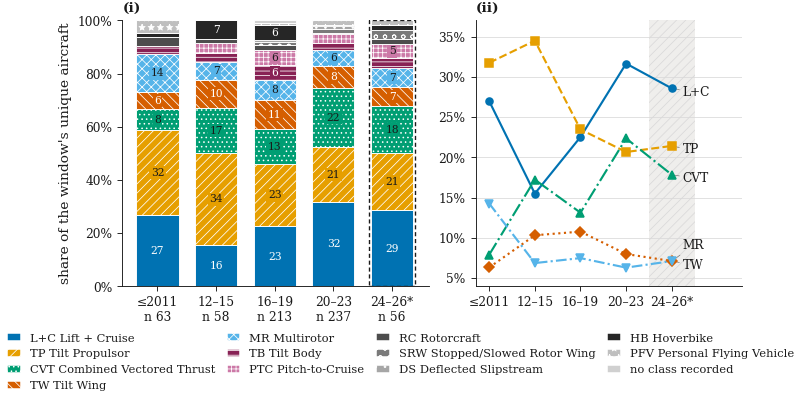

In [6]:
codes10 = [c for c in style.CLASS_ORDER if c in cnt.columns] + ['Other']      # Other: the aircraft with no class recorded
five = ['SLC', 'TR', 'CVT', 'TW', 'MR']
tick10 = [f"{WSHORT.get(w, '24–26*')}\nn {int(n)}" for w, n in zip(WIN_NAMES, n_win)]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(W, 3.7), constrained_layout=True, gridspec_kw={'width_ratios': [1.15, 1]})
sh = share[codes10].copy(); sh.index = list(range(len(sh)))
plots.share_bars(ax, sh, partial=[len(sh) - 1], min_label=0.05, label_kind='pct')
ax.set_xticks(range(len(WIN_NAMES)), tick10); style.mark(ax, '(i)')
ax.set_ylabel("share of the window's unique aircraft")
lines = share[five].copy(); lines.index = list(range(len(lines)))
plots.window_lines(ax2, lines, n_few=0, ticks=[WSHORT.get(w, '24–26*') for w in WIN_NAMES])
ax2.axvspan(len(WIN_NAMES) - 1.5, len(WIN_NAMES) - 0.5, facecolor=plots.FEW_FILL, hatch=style.PARTIAL_HATCH, edgecolor=style.GRID, linewidth=0, zorder=0)
ax2.set_xlim(-0.3, len(WIN_NAMES) + 0.55)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0)); ax2.grid(axis='y', color=style.GRID, linewidth=0.5); ax2.set_axisbelow(True)
ax2.set_ylim(0.04, 0.37)
last = lines.iloc[-1]
plots.end_labels(ax2, len(WIN_NAMES) - 1, [last[c] for c in five], [style.cls(c).short for c in five], [style.cls(c).color for c in five], gap=0.024)
style.mark(ax2, '(ii)')
fig.legend(handles=style_legend(codes10), loc='outside lower center', ncol=4, fontsize=7.5, handlelength=1.2, columnspacing=1.0)
plt.show()
fig10_data = share.round(4).assign(aircraft=n_win)
save.figure(fig, cfg, 'q3', 'fig_10_class_mix_by_window', data=fig10_data,
            caption='architecture mix per priority window, counted in unique aircraft (not patents). (i) architecture share per window; (ii) the five largest classes over time.',
            source='human labelling (class) · PatSeer (priority date)',
            unit=f"unique aircraft ({int(n_win.sum())}) per four-year priority window; the window 2024-26 is still filling (hatched, dashed frame, star)",
            read="(i) Each bar is 100 % of one window; a segment of 5 % or more prints its share in percent, smaller ones are in the key. The number under each window is its aircraft. (ii) The five largest classes: one line each, in the class's colour, dash and marker; the line ends are named. Shares are read, never counts, because a share can fall while the count grows. The earliest window rests on few aircraft, so its shares are coarse.",
            panels={'(i)': 'class share per window', '(ii)': 'the five largest classes over time'})
plt.close(fig)

### The directory's dating

The evtol.news directory (crawled 2026-09-17) is dated by development year; two readers each named the dating sentence. The table counts, per directory class, the aircraft on the list, those the readers agree on (used), those they disagree on (left out until the author rules) and those whose page states no year (`frames.evtolnews_coverage`); it is checked against the document. The comparison of the two mixes is Figure 2, in chapter 1.

In [7]:
cov = frames.evtolnews_coverage(cfg)
verify(cov, 'la_evtolnews_coverage', key=['directory class'])
save.table(cov, cfg, 'q3', 'tab_dating_evtolnews', caption='The evtol.news directory aircraft by the dating of their development year, per directory class.',
           source='evtol.news directory (Vertical Flight Society), crawled 2026-09-17; development year read by two readers (language-model instances)')
cov

,la_evtolnews_coverage
table,la_evtolnews_coverage
rows (notebook | document),6 | 6
cells compared,48
matched,48
expected differences,0
differences,0
status,match


,directory class,aircraft on the list,agreed by both readers,ruled by the author,"conflict, not yet ruled",not stated on the page,dated (in the panel),undated (left out),dated share
0,Lift + Cruise,225,190,0,11,24,190,35,0.844
1,Vectored Thrust,426,341,0,26,59,341,85,0.800
2,Wingless (Multicopter),365,289,0,17,59,289,76,0.792
3,Electric Rotorcraft,86,76,0,6,4,76,10,0.884
4,Hover Bikes / Personal Flying Devices,127,104,0,3,20,104,23,0.819
5,all classes,1229,1000,0,63,166,1000,229,0.814


### 3.1 numbers

In [8]:
allc = cov.set_index('directory class').loc['all classes']
N1 = {'tk_tr_w1': pct(share.loc['<= 2011', 'TR']), 'tk_tr_w4': pct(share.loc['2020-23', 'TR']),
      'tk_slc_w1': pct(share.loc['<= 2011', 'SLC']), 'tk_slc_w4': pct(share.loc['2020-23', 'SLC']),
      'sm_evn_list': thin(allc['aircraft on the list']), 'sm_evn_agreed': thin(allc['agreed by both readers']),
      'sm_evn_dated': thin(allc['dated (in the panel)']), 'sm_evn_conflict': thin(allc['conflict, not yet ruled']),
      'sm_evn_notstated': thin(allc['not stated on the page']), 'sm_evn_dated_share': pct(allc['dated share']),
      'sm_evn_min_n': str(cfg.analysis['evtolnews_min_n'])}
numbers_check(N1)
print('also quoted in the takeaway: with CVT', pct(share.loc['2020-23', 'CVT']), 'the three hold', pct(share.loc['2020-23', ['SLC', 'TR', 'CVT']].sum()),
      'of the 2020-23 aircraft; the earliest window rests on', int(n_win['<= 2011']), 'aircraft against', int(n_win['2020-23']), '; 2016-19: TP', pct(share.loc['2016-19', 'TR']), 'L+C', pct(share.loc['2016-19', 'SLC']))

,name,notebook,document,match
0,tk_tr_w1,32 %,32 %,yes
1,tk_tr_w4,21 %,21 %,yes
2,tk_slc_w1,27 %,27 %,yes
3,tk_slc_w4,32 %,32 %,yes
4,sm_evn_list,1 229,1 229,yes
5,sm_evn_agreed,1 000,1 000,yes
6,sm_evn_dated,1 000,1 000,yes
7,sm_evn_conflict,63,63,yes
8,sm_evn_notstated,166,166,yes
9,sm_evn_dated_share,81 %,81 %,yes


also quoted in the takeaway: with CVT 22 % the three hold 75 % of the 2020-23 aircraft; the earliest window rests on 63 aircraft against 237 ; 2016-19: TP 23 % L+C 23 %


## 3.2 — Is there a dominant design?

#### Method

**Objective.** Whether the sector has settled on a **dominant design**, the design most new products follow after a period of competing alternatives, after which change moves from the concept to its parts (Abernathy and Utterback, 1978). A design has two sides: its **morphology**, the arrangement (the form, number, size and placement of wings, booms and propulsor units), and its **functional allocation**, which components do which duty in hover and in cruise. A Lift + Cruise and a CVT can share the same outline, a fixed wing carrying propulsor sets, and differ in the allocation: separate propulsor units for each regime against one tilting set doing both.


**Data and unit of analysis.** The unique aircraft, in the four archetype sets of chapter 2: C (class), C·W·T (class + wings + tilt), C·U (class + propulsor units) and **F**, the Lift + Cruise family: every Lift + Cruise aircraft plus every CVT aircraft whose tilting propulsor set sits on a wing that does not tilt (2.2). F groups on morphology alone: both are a fixed wing carrying propulsors spread over the airframe, and they part on the functional allocation. Sources: human labelling (class, wings, tilt, propulsor units, every field of the distance), PatSeer (priority date; legal status at the snapshot, 2026-06-08).

**Procedure.** A patent record has no sales, so the idea is tested through three conditions of different kinds, counts, balance and form. A dominant design needs all three in the same period: condition 1's two years inside a complete window in which conditions 2 and 3 are met. The graphs follow the conditions.

- **Condition 1, counts: is most of the sector proposing the same design?** Figure 11 shows F's share of the aircraft of each priority year on two bases: the aircraft with at least one patent in force at the snapshot, granted and alive or still under examination, as defined in 1.2 (main, solid line), and every aircraft of the year (dashed). Years are read from 2016 (in force) and 2015 (all), where the base holds 20 aircraft or more, to 2023; under each year the graph prints the aircraft in force, all aircraft, and the share of the in-force aircraft with a granted patent. *Met when* one archetype holds more than 50 % in two consecutive read years (ringed in red). It moves only when one archetype's share rises while all the others fall; two designs sharing the field do not meet it. C, C·W·T and C·U are read the same way and reported in Table 8.
- **Condition 2, balance: are fewer designs in play than chance gives?** Figure 12 (i) shows, per four-year window and archetype set, ²D (how many large designs are in play, box of 2.2) against its permutation band (grey): the middle 95 % of the ²D values obtained when the aircraft are shuffled among the windows at random (box of chapter 1). ²D is rarefied to 40 aircraft because it needs a sample of the same size in every window to be compared, and it is read per window because single years are too small for that sample. The 40 are drawn at random from the window's aircraft, and the draw is repeated 300 times and averaged, so every aircraft has the same chance of entering and no single sample decides the value. *Met when* ²D falls below the band (red point): the window holds fewer designs in play than the same aircraft dealt into windows at random.
- **Condition 3, form: have the aircraft themselves become alike?** Figure 12 (ii) shows ΔQ per window against its permutation band. Q is the average Gower distance between two aircraft of the window (Rao's quadratic entropy; formulas in the box of 2.2): 0 when two aircraft answer every design field alike, 1 when they share none. ΔQ is the window's Q minus the average Q of the two earliest windows. The fields compared are the class; wing count, arrangement, vertical and lateral position and planform; empennage type and count; fuselage count, shape, body motion, symmetry and landing gear; whether the wing carries thrust and how many propulsor units it carries; propulsor units, any tilting propulsor unit, fixed and tilting propulsor units mixed, any ducted propulsor unit, all propulsor units ducted. **The main weighting** (solid) gives each of the six subsystems (class, wings, tail, body, booms, propulsion) the same total weight, shared among its fields, so a subsystem described by many fields does not outweigh one described by few; this is the weighting that matters most, because the six subsystems play a similar visual role, each taking a similar share of the visual morphological representation of an aircraft. **The check** (dashed, dotted band) gives every field the same weight, so the propulsion fields, the most numerous, carry the largest part of it. *Met when* ΔQ falls below its band (red point). Q uses no archetype: C, C·U and F read the same aircraft, give identical values and share one panel; C·W·T leaves out the few aircraft whose wings or tilt are not recorded. So Q can fall when aircraft converge on one layout under different class names, while conditions 1 and 2 need not move.
- Table 8 marks, per condition and archetype set, whether the condition is met (✓) or not (✗), naming the years or windows.

**Scientific grounds.** Condition 1 carries Anderson and Tushman (1990), more than 50 % of new product sales in four consecutive years, over to a patent record; on its eight read years, two consecutive years are asked. Its main base is the in-force set: a dominant design is the design most new products follow, a patent record has no sales, and renewal fees are the one place where a firm votes with money on the designs it still values, so the aircraft still in force are the closest substitute; all aircraft are kept beside them as the check. Conditions 2 and 3 measure what the literature states in words: variety collapses (Utterback), the core subsystems converge (Murmann and Frenken, 2006). The shakeout test of Suárez and Utterback (1995) is not run: most active firms are still filing for the first time, so there are no exits to date it by.

**Assumptions and limits.** The thresholds (50 %, the bands) were fixed before any curve was drawn. Chosen after the first readings of the data: the yearly step of condition 1 (a dominant design is a claim about the latest years, which a four-year window blurs), its in-force base, and F. F was defined to test whether the general morphology could be grouped, because the boom and propulsor-unit patterns had made Lift + Cruise and the fixed-wing CVT look alike; CVT with propulsor units on booms and Tilt Propulsor with CVT were considered and not used. Merging archetypes adds their shares, so grouping alone can pass condition 1; it cannot pass conditions 2 and 3, since the band of condition 2 is rebuilt from the grouped archetypes and Q uses none. 2022 and 2023 are the least complete years: only 80 % and 34 % of their in-force aircraft hold a granted patent, against 94 % and 92 % in 2020 and 2021, and 23.8 % of the 2022 families and 56.5 % of the 2023 ones are neither granted nor refused.

**The frame the result is read in: eras of a technology cycle.** Anderson and Tushman (1990) describe a technology as moving through a cycle:

1. a **technological discontinuity**: a new core concept opens a new design space (for eVTOL, the candidate the literature names is distributed electric propulsion, which makes vertical take-off on many small propulsors possible; this labelled dataset does not test it);
2. an **era of ferment**: rival concepts compete, variety is high, and each firm bets on its own layout;
3. a **dominant design** is selected;
4. an **era of incremental change**: the concept is fixed and effort moves to refining its parts, until the next discontinuity.

The two kinds of innovation map onto the eras. A **radical** innovation changes the core concept: how the aircraft passes from hover to cruise, which is what the architecture class records. An **incremental** innovation refines a concept that is kept: more propulsors, a duct, a folding blade, a second tilting set on the same layout. An era of ferment is dominated by the first kind; an era of incremental change by the second.

What each era predicts on the measures of this chapter:

| measure | era of ferment | dominant design emerging | incremental change |
|---|---|---|---|
| largest archetype share (condition 1) | well below half | rising toward half | above half |
| ²D (condition 2) | high: many designs in play | falls below the band | low: one or two |
| Q (condition 3) | high: aircraft unlike each other | clear drop | low |
| where change happens | the class itself (radical) | from the class to its parts | the parts (incremental) |

The sector is placed in an era by reading the three conditions together, and the within-class readings of 3.3 say whether change inside each class is already incremental while the classes themselves still compete.

### Condition 1: the largest archetype per priority year

`frames.dd_yearly` gives, per archetype set (C, C·W·T, C·U, F) and base (the aircraft with at least one patent in force, and every aircraft of the year), the largest archetype's share of each priority year 2008-2023 (`lib.dominant_design.yearly_top_share`: the largest archetype and its share, ties by first appearance, a year is read when its base holds 20 aircraft or more). `frames.family_yearly` is the same for F with the share of the in-force aircraft that hold a granted patent. Both are checked against the document. F is every Lift + Cruise aircraft plus every CVT aircraft whose tilting propulsor set sits on a wing that does not tilt (`frames.family_flags`, `frames.family_mask`).

In [9]:
fy = frames.family_yearly(ds, v, LAST)
verify(fy, 'la_family_yearly', key=['priority year'])
dy = frames.dd_yearly(ds, v, LAST)
verify(dy, 'la_dd_yearly', key=['level id', 'base', 'priority year'])
fy

,la_family_yearly
table,la_family_yearly
rows (notebook | document),16 | 16
cells compared,160
matched,160
expected differences,0
differences,0
status,match


,la_dd_yearly
table,la_dd_yearly
rows (notebook | document),128 | 128
cells compared,1024
matched,1024
expected differences,0
differences,0
status,match


,priority year,aircraft,F aircraft,F share,aircraft in force,F aircraft in force,F share in force,in force with a granted patent,"F share, granted and live","read, in force","read, all"
0,2008,6,1,0.1667,3,0,0.0000,1.0000,0.0000,False,False
1,2009,7,3,0.4286,3,1,0.3333,1.0000,0.3333,False,False
2,2010,6,1,0.1667,3,1,0.3333,1.0000,0.3333,False,False
3,2011,14,7,0.5000,4,2,0.5000,1.0000,0.5000,False,False
4,2012,14,1,0.0714,9,1,0.1111,1.0000,0.1111,False,False
5,2013,11,2,0.1818,4,1,0.2500,1.0000,0.2500,False,False
6,2014,12,2,0.1667,6,1,0.1667,1.0000,0.1667,False,False
7,2015,21,8,0.3810,14,4,0.2857,0.9286,0.3077,False,True
8,2016,34,8,0.2353,24,6,0.2500,1.0000,0.2500,True,True
9,2017,52,12,0.2308,33,6,0.1818,0.9697,0.1562,True,True


### Figure 11 — condition 1 on F, per priority year

F's share of the year's aircraft on the two bases against the 50 % line. A year is read when its base holds 20 aircraft or more (from 2016 in force, from 2015 on all aircraft); condition 1 is met when one archetype is above 50 % in two consecutive read years (`lib.dominant_design.condition1_years`), ringed in red. Under each year: the aircraft in force, all aircraft, and the share of the in-force aircraft with a granted patent.

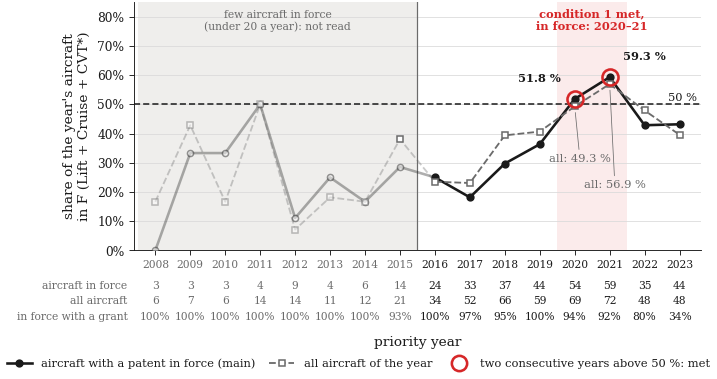

In [10]:
yrs = fy['priority year'].to_numpy()
met = sorted(dominant_design.condition1_years(pd.DataFrame({'priority year': yrs, 'read': fy['read, in force'], 'above 50 %': fy['F share in force'] > 0.5})))
first_read = int(yrs[fy['read, in force'].to_numpy()][0])
fig, ax = plt.subplots(figsize=(W, 3.5), constrained_layout=True)
plots.condition1_years(ax, yrs, fy['F share in force'], fy['F share'], fy['read, in force'], fy['read, all'], met, first_read,
                       f"few aircraft in force\n(under {cfg.analysis['trend_min_n']} a year): not read")
fi, fa = fy.set_index('priority year')['F share in force'], fy.set_index('priority year')['F share']
for k, y in enumerate(met):                                  # the shares of the two met years, both bases
    side = -1 if k == 0 else 1
    ax.annotate(pct1(fi[y]), (y, fi[y]), textcoords='offset points', xytext=(side * 9, 10), ha='right' if side < 0 else 'left', va='bottom',
                fontsize=7.5, fontweight='bold', color=style.INK)
    ax.annotate(f"all: {pct1(fa[y])}", (y, fa[y]), xytext=(y + 0.15, 0.33 if k == 0 else 0.24), textcoords='data', ha='center', va='top', fontsize=7.5,
                color=style.MUTED, arrowprops=dict(arrowstyle='-', color=style.MUTED, linewidth=0.5, shrinkA=1, shrinkB=4))
ax.text((met[0] + met[-1]) / 2, 0.975, f"condition 1 met,\nin force: {met[0]}–{str(met[-1])[-2:]}", ha='center', va='top', fontsize=7.5,
        color=plots.MET, fontweight='bold', transform=ax.get_xaxis_transform())
ax.text(yrs[-1] + 0.5, 0.505, '50 %', ha='right', va='bottom', fontsize=7.5)
ax.set_ylabel("share of the year's aircraft\nin F (Lift + Cruise + CVT*)")
ax.set_xticks(yrs, [str(y) for y in yrs], fontsize=7)
from matplotlib.transforms import offset_copy
rows3 = [('aircraft in force', fy['aircraft in force']), ('all aircraft', fy['aircraft']),
         ('in force with a grant', fy['in force with a granted patent'].map(lambda g: '–' if not np.isfinite(g) else f'{100 * g:.0f}%'))]
for r, (name, vals) in enumerate(rows3):
    tr_ = offset_copy(ax.get_xaxis_transform(), fig=fig, y=-(20 + 10 * r), units='points')
    ax.text(-0.012, 0, name, transform=offset_copy(ax.transAxes, fig=fig, y=-(20 + 10 * r), units='points'), ha='right', va='top', fontsize=7, color=style.MUTED)
    for y_, t_, rd in zip(yrs, vals, fy['read, in force']):
        ax.text(y_, 0, str(t_), transform=tr_, ha='center', va='top', fontsize=7, color=style.INK if rd else style.MUTED)
for lab, rd in zip(ax.get_xticklabels(), fy['read, in force']):
    if not rd:
        lab.set_color(style.MUTED)
ax.set_xlabel('priority year', labelpad=43)
h = [Line2D([], [], color=style.INK, linewidth=1.7, marker='o', markersize=4.4, label='aircraft with a patent in force (main)'),
     Line2D([], [], color=style.MUTED, linewidth=1.2, linestyle='--', marker='s', markersize=4.2, markerfacecolor='white', label='all aircraft of the year'),
     Line2D([], [], marker='o', markersize=10, markerfacecolor='none', markeredgecolor=plots.MET, markeredgewidth=1.7, linestyle='none', label='two consecutive years above 50 %: met')]
fig.legend(handles=h, loc='outside lower center', ncol=3, fontsize=7.5, handlelength=2.2, columnspacing=1.2)
plt.show()
save.figure(fig, cfg, 'q3', 'fig_11_condition1_family', data=fy,
            caption='condition 1 on F, the Lift + Cruise family (defined after the first readings of the data), per priority year: its share of the aircraft with a patent in force and of all aircraft, against the 50 % line.',
            source='human labelling (class; the family F, defined after the first readings of the data) · PatSeer (priority date; legal status at the snapshot, 2026-06-08)',
            unit=f"unique aircraft by priority year, 2008-2023; F = every Lift + Cruise aircraft plus every CVT aircraft whose tilting propulsor set sits on a wing that does not tilt (CVT*); a year is read when its base holds {cfg.analysis['trend_min_n']} aircraft or more",
            read="Solid line, dots: F's share of the aircraft with at least one patent in force (granted and alive, or still under examination), the main base; dashed line, squares: F's share of every aircraft of the year. Dashed black line: 50 %. Condition 1 is met when the share is above 50 % in two consecutive read years: the ringed years and the red band. Faded years, left of the vertical line, hold fewer than 20 aircraft on the in-force base and are not read. Under each year: the aircraft in force, all aircraft, and the share of the in-force aircraft whose patent is granted (a low share is a base still made of pending applications).")
plt.close(fig)

### Conditions 2 and 3: balance and form

*Condition 2* (`frames.dd_balance_table` → `lib.dominant_design.balance_band`): per window and archetype set, ²D rarefied to 40 aircraft (300 draws averaged) against the middle 95 % of the ²D of the same archetypes shuffled among the windows (200 permutations, seed 42; C·U then C·W·T share one generator in that order, C and F each start a new one, as in the document). *Condition 3* (`frames.dd_form_table` → `lib.distance.gower_distance`, `lib.dominant_design.cohesion_band`): Q, the average Gower distance between two aircraft of the window under the main weighting (every subsystem equal) and the check (every field equal), ΔQ against the two earliest windows, and the band of ΔQ when the aircraft are shuffled among the windows. Q uses no archetype: C, C·U and F read the same aircraft (F's row is C's), C·W·T leaves out the aircraft whose wings or tilt are not recorded. Both tables are checked against the document.

In [11]:
bal = frames.dd_balance_table(ds, v, WIN_NAMES, cfg.analysis['rarefy_n'], 200, SEED)
verify(bal, 'la_dd_balance', key=['level', 'window'])
form = frames.dd_form_table(ds, v, WIN_NAMES, 200, SEED)
verify(form, 'la_dd_form', key=['level', 'weighting', 'window'])
bal[['level name', 'window', 'aircraft', 'D2', 'D2 permutation low', 'D2 permutation high', 'below band']]

,la_dd_balance
table,la_dd_balance
rows (notebook | document),20 | 20
cells compared,260
matched,260
expected differences,0
differences,0
status,match


,la_dd_form
table,la_dd_form
rows (notebook | document),40 | 40
cells compared,360
matched,360
expected differences,0
differences,0
status,match


,level name,window,aircraft,D2,D2 permutation low,D2 permutation high,below band
0,C — Class,<= 2011,63,4.66,4.15,6.43,False
1,C — Class,2012-15,58,5.00,4.08,6.38,False
2,C — Class,2016-19,211,5.96,4.72,5.77,False
3,C — Class,2020-23,237,4.53,4.74,5.80,True
4,C — Class,2024-26 (partial),56,5.56,4.04,6.59,False
5,C·W·T — Class + wings + tilt,<= 2011,63,8.25,7.09,11.53,False
6,C·W·T — Class + wings + tilt,2012-15,58,8.08,6.99,12.31,False
7,C·W·T — Class + wings + tilt,2016-19,211,10.56,8.31,10.51,False
8,C·W·T — Class + wings + tilt,2020-23,236,8.34,8.24,10.34,False
9,C·W·T — Class + wings + tilt,2024-26 (partial),55,9.16,7.12,12.38,False


### Figure 12 — conditions 2 and 3 per window

(i) ²D against its permutation band in the four archetype sets; (ii) ΔQ against its band, main weighting (solid, grey band) and check (dashed, dotted band edges). A red point is a window where the condition is met (below the band). The partial window is hatched and not read.

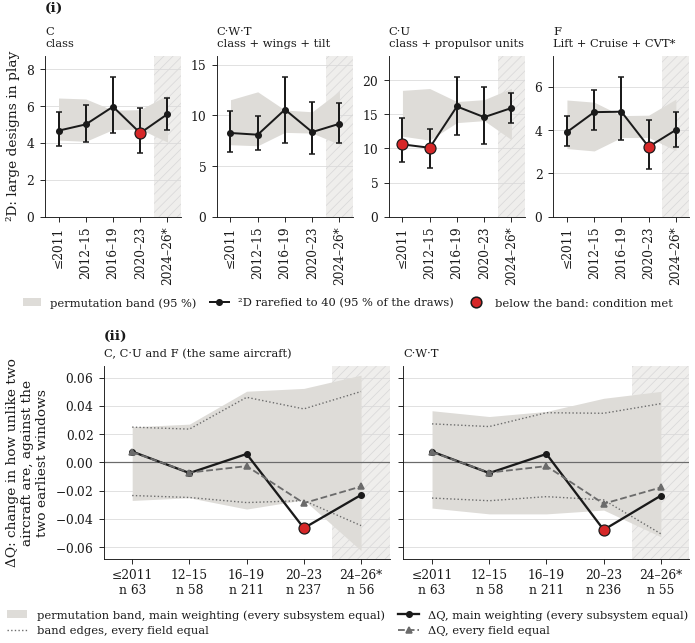

In [12]:
LEVELS = frames.DD_LEVELS
TITLE = {'A0': 'C\nclass', 'A1t': 'C·W·T\nclass + wings + tilt', 'A0c': 'C·U\nclass + propulsor units', 'family_b': 'F\nLift + Cruise + CVT*'}
partial = [('partial' in w) for w in WIN_NAMES]
tk = [TICK[w] for w in WIN_NAMES]
fig = plt.figure(figsize=(W, 5.9), constrained_layout=True)
top, bot = fig.subfigures(2, 1, height_ratios=[1.0, 1.0])
axs = top.subplots(1, 4)
for ax, lvl in zip(axs, LEVELS):
    s = bal[bal['level'] == lvl].set_index('window').reindex(WIN_NAMES)
    metw = [bool(s.loc[w, 'below band']) and 'partial' not in w for w in WIN_NAMES]
    plots.balance_panel(ax, s.reset_index(), partial, metw, tk)
    ax.set_title(TITLE[lvl], fontsize=7.5, loc='left')
axs[0].set_ylabel('²D: large designs in play')
style.mark(axs[0], '(i)', lines_up=2.1)
top.legend(handles=[Patch(facecolor='#dedcd8', label='permutation band (95 %)'),
                    Line2D([], [], color=style.INK, marker='o', markersize=3.6, linewidth=1.3, label='²D rarefied to 40 (95 % of the draws)'),
                    Line2D([], [], marker='o', markersize=7, color=plots.MET, markeredgecolor=style.INK, linestyle='none', label='below the band: condition met')],
           loc='outside lower center', ncol=3, fontsize=7.5, handlelength=1.6, columnspacing=1.2)
axb = bot.subplots(1, 2, sharey=True)
main, alt = frames.Q_WEIGHTINGS
for ax, lvl, ttl in zip(axb, ('A0', 'A1t'), ('C, C·U and F (the same aircraft)', 'C·W·T')):
    s = form[form['level'] == lvl]
    sm = s[s['weighting'] == main].set_index('window').reindex(WIN_NAMES).reset_index()
    su = s[s['weighting'] == alt].set_index('window').reindex(WIN_NAMES).reset_index()
    plots.cohesion_panel(ax, sm, su, partial, [f"{WSHORT.get(w, '24–26*')}\nn {int(n)}" for w, n in zip(WIN_NAMES, sm['aircraft'])])
    ax.set_title(ttl, fontsize=7.5, loc='left')
axb[0].set_ylabel('ΔQ: change in how unlike two\naircraft are, against the\ntwo earliest windows')
style.mark(axb[0], '(ii)', lines_up=1.1)
bot.legend(handles=[Patch(facecolor='#dedcd8', label='permutation band, main weighting (every subsystem equal)'),
                    Line2D([], [], color=style.MUTED, linestyle=':', linewidth=0.9, label='band edges, every field equal'),
                    Line2D([], [], color=style.INK, marker='o', markersize=3.6, linewidth=1.5, label='ΔQ, main weighting (every subsystem equal)'),
                    Line2D([], [], color=style.MUTED, marker='^', markersize=3.8, linewidth=1.2, linestyle='--', label='ΔQ, every field equal')],
           loc='outside lower center', ncol=2, fontsize=7.5, handlelength=1.8, columnspacing=1.2)
plt.show()
fig12_data = pd.concat([bal.assign(condition='2, balance'), form.assign(condition='3, form')], ignore_index=True)
save.figure(fig, cfg, 'q3', 'fig_12_conditions_2_3', data=fig12_data,
            caption='conditions 2 and 3 of the dominant-design test per window in the four archetype sets C, C·W·T, C·U and F; a red point is an archetype-set window where the condition is met; condition 3 under the main weighting (every subsystem equal) and the check (every field equal).',
            source='human labelling (class, wings, tilt, propulsor units, every field of the distance) · PatSeer (priority date)',
            unit=f"unique aircraft per four-year priority window (C: {int(bal[(bal['level'] == 'A0') & (bal['window'] == '2020-23')]['aircraft'].iloc[0])} in 2020-23); 200 permutations, seed 42; ²D rarefied to {cfg.analysis['rarefy_n']} aircraft (300 draws); the partial window 2024-26 is hatched and not read; F = Lift + Cruise + CVT*, defined after the first readings of the data",
            read="(i) Dot: the window's ²D (how many large designs are in play) averaged over the rarefaction draws, whisker: the middle 95 % of the draws. Grey band: the middle 95 % of the ²D of the same archetypes shuffled among the windows at random, window sizes kept. A red dot is below the band: fewer designs in play than chance gives, condition 2 met. (ii) Q is the average Gower distance between two aircraft of the window (0 = alike on every design field, 1 = no field shared); ΔQ is the window's Q minus the average Q of the two earliest windows. Grey band: the middle 95 % of ΔQ when the aircraft are shuffled among the windows; a red dot is below it (condition 3 met). Solid line and band: every subsystem weighs the same (the main weighting); dashed line and dotted edges: every field weighs the same (the check). C, C·U and F read the same aircraft and share one panel; C·W·T leaves out the aircraft whose wings or tilt are not recorded.",
            panels={'(i)': 'condition 2: ²D against its permutation band, four archetype sets', '(ii)': 'condition 3: ΔQ against its permutation band, both weightings'})
plt.close(fig)

### Table 8 — the dominant-design verdict

`frames.dd_levels` writes, per condition and archetype set, where the condition is met (the years for condition 1, the windows for 2 and 3), by the rules of `lib.dominant_design` (`condition1_years`, `all_three_windows`). The raw table is checked against the document's `la_dd_levels`; the printed table (✓ met, ✗ not met) against the document's Table 8 as printed in the text.

In [13]:
lv = frames.dd_levels(dy, bal, form, WIN_NAMES)
verify(lv, 'la_dd_levels', key=['condition'])
import re
def printed(cell):
    c = re.sub(r'(in force|all): no — ', r'\1: ✗ not met, ', cell)
    c = re.sub(r'(in force|all): met in', r'\1: ✓ met in', c)
    c = re.sub(r'^met in', '✓ met in', c)
    return '✗ not met' if c == 'no' else c
t8 = lv.copy()
t8['condition'] = t8['condition'].str.replace(' — ', ', ', n=1)
for c in t8.columns[1:]:
    t8[c] = t8[c].map(printed)
t8.columns = ['condition', 'C', 'C·W·T', 'C·U', 'F (defined after the first readings)']
doc8 = checks.brief_table(cfg, 8)
verify(t8, None, 'Table 8 as printed in the document', doc_wording=False, key=['condition'], ref_frame=doc8)
save.table(t8, cfg, 'q3', 'tab_8_dominant_design_verdict', caption='The dominant-design verdict per condition and archetype set, naming the priority years (condition 1) or windows (conditions 2 and 3) where each condition is met (✓) or not (✗). Condition 1 on the aircraft with a patent in force (main) and on all aircraft; condition 3 under the main weighting. F was defined after the first readings of the data.', source='human labelling · PatSeer (priority date; legal status at the snapshot, 2026-06-08)')
t8

,la_dd_levels
table,la_dd_levels
rows (notebook | document),4 | 4
cells compared,16
matched,16
expected differences,0
differences,0
status,match


,Table 8 as printed in the document
table,Table 8 as printed in the document
rows (notebook | document),4 | 4
cells compared,16
matched,16
expected differences,0
differences,0
status,match


,condition,C,C·W·T,C·U,F (defined after the first readings)
0,"1, counts: one archetype above 50 % of the aircraft, two consecutive priority years","in force: ✗ not met, at most 39.0 % (2021); all: ✗ not met, at most 36.2 % (2020)","in force: ✗ not met, at most 27.1 % (2021); all: ✗ not met, at most 27.3 % (2018)","in force: ✗ not met, at most 23.7 % (2021); all: ✗ not met, at most 19.4 % (2021)","in force: ✓ met in 2020 and 2021 (51.8 %, 59.3 %); all: ✗ not met, above half only in 2021 (56.9 %), not 2020 (49.3 ..."
1,"2, balance: ²D below the permutation band",✓ met in 2020-23,✗ not met,"✓ met in <= 2011, 2012-15",✓ met in 2020-23
2,"3, form: Q below the two earliest windows by more than the band",✓ met in 2020-23,✓ met in 2020-23,✓ met in 2020-23,✓ met in 2020-23
3,all three in the same period,✗ not met,✗ not met,✗ not met,✓ met in 2020-23


### 3.2 numbers

The in-force and all-aircraft shares of F by year, the largest archetype of the other three sets, the apparatus constants of the Method, the granted-and-live check, and the external comparison of the Answer: of the AAM Reality Index firms that disclose funding, the share of their aircraft in F weighted by funding (`frames.ari_f_funding`), against F's share of the whole corpus (Table 7 of chapter 2).

In [14]:
fyi = fy.set_index('priority year')
words = {6: 'six', 7: 'seven', 8: 'eight', 9: 'nine', 10: 'ten'}
rest = dy[dy['read'] & dy['base'].eq('in force') & ~dy['level id'].eq('family_b')]
levels = frames.archetype_levels_table(ds, v, cfg)
brief7 = frames.archetype_levels_brief(ds, v, levels).set_index('level id')
ext = frames.ari_f_funding(ds, v, cfg)
N2 = {'sm_dd_year_min': str(cfg.analysis['trend_min_n']), 'sm_dd_read_years': words[int(fy['read, in force'].sum())],
      'sm_fy_first': str(first_read), 'sm_fy_first_all': str(int(yrs[fy['read, all'].to_numpy()][0])),
      'sm_dd_max_rest': pct1(float(rest['its share'].max())),
      'sm_fy_fa_2020': pct1(fyi.loc[2020, 'F share']), 'sm_fy_fak_2020': str(int(fyi.loc[2020, 'F aircraft'])), 'sm_fy_na_2020': str(int(fyi.loc[2020, 'aircraft'])),
      'sm3_f_gl_2020': pct(fyi.loc[2020, 'F share, granted and live']), 'sm3_f_gl_2021': pct(fyi.loc[2021, 'F share, granted and live']),
      'sm_ext_f_weighted': pct(ext.iloc[-1]['funding-weighted F share']), 'sm_ext_f_corpus': pct(brief7.loc['family_b', 'its share']),
      'c4_fund_n': str(int((ext['kind'] == 'firm').sum()))}
for y in (2020, 2021, 2022, 2023):
    N2[f'sm_fy_fi_{y}'] = pct1(fyi.loc[y, 'F share in force'])
    N2[f'sm_fy_gl_{y}'] = pct(fyi.loc[y, 'in force with a granted patent'])
numbers_check(N2)

,name,notebook,document,match
0,sm_dd_year_min,20,20,yes
1,sm_dd_read_years,eight,eight,yes
2,sm_fy_first,2016,2016,yes
3,sm_fy_first_all,2015,2015,yes
4,sm_dd_max_rest,39.0 %,39.0 %,yes
5,sm_fy_fa_2020,49.3 %,49.3 %,yes
6,sm_fy_fak_2020,34,34,yes
7,sm_fy_na_2020,69,69,yes
8,sm3_f_gl_2020,53 %,53 %,yes
9,sm3_f_gl_2021,59 %,59 %,yes


In [15]:
# also quoted in the takeaways and the verdict of 3.2 (not in the document's number list): each against the figure the document prints
b = bal.set_index(['level', 'window']); q = form.set_index(['level', 'weighting', 'window'])
topshare = lambda lvl: float(dy[(dy['level id'] == lvl) & (dy['base'] == 'in force') & dy['read']]['its share'].max())
top3 = lambda sid: frames.archetype_key(v[v['window'] == '2020-23'], sid).value_counts(normalize=True).head(3).sum()
EXTRA = {
    'F 2D 2020-23': (f"{b.loc[('family_b', '2020-23'), 'D2']:.2f}", '3.22'), 'F band edge': (f"{b.loc[('family_b', '2020-23'), 'D2 permutation low']:.2f}", '3.65'),
    'C 2D 2020-23': (f"{b.loc[('A0', '2020-23'), 'D2']:.2f}", '4.53'), 'C band edge': (f"{b.loc[('A0', '2020-23'), 'D2 permutation low']:.2f}", '4.74'),
    'C·U 2D <=2011': (f"{b.loc[('A0c', '<= 2011'), 'D2']:.2f}", '10.60'), 'C·U edge <=2011': (f"{b.loc[('A0c', '<= 2011'), 'D2 permutation low']:.2f}", '11.80'),
    'C·U 2D 2012-15': (f"{b.loc[('A0c', '2012-15'), 'D2']:.2f}", '10.10'), 'C·U edge 2012-15': (f"{b.loc[('A0c', '2012-15'), 'D2 permutation low']:.2f}", '11.22'),
    'dQ main 2020-23': (f"{q.loc[('A0', 'subsystem', '2020-23'), 'ΔQ']:+.3f}".replace('-', '−'), '−0.047'),
    'dQ main edge': (f"{q.loc[('A0', 'subsystem', '2020-23'), 'ΔQ permutation low']:+.3f}".replace('-', '−'), '−0.027'),
    'dQ every field equal': (f"{q.loc[('A0', 'uniform', '2020-23'), 'ΔQ']:+.3f}".replace('-', '−'), '−0.029'),
    'dQ every field equal edge': (f"{q.loc[('A0', 'uniform', '2020-23'), 'ΔQ permutation low']:+.3f}".replace('-', '−'), '−0.027'),
    'max C in force': (pct1(topshare('A0')), '39.0 %'), 'max C·W·T in force': (pct1(topshare('A1t')), '27.1 %'), 'max C·U in force': (pct1(topshare('A0c')), '23.7 %'),
    'F in force 2021': (f"{int(fyi.loc[2021, 'F aircraft in force'])} of {int(fyi.loc[2021, 'aircraft in force'])}", '35 of 59'),
    'F in force 2020': (f"{int(fyi.loc[2020, 'F aircraft in force'])} of {int(fyi.loc[2020, 'aircraft in force'])}", '28 of 54'),
    'top three C·W·T 2020-23': (pct(top3('A1t')), '47 %'), 'top three C·U 2020-23': (pct(top3('A0c')), '26 %'),
    'F share 2022 in force': (pct1(fyi.loc[2022, 'F share in force']), '42.9 %'),
}
extra = pd.DataFrame([{'quoted': k, 'notebook': m, 'document': d, 'match': 'yes' if m == d else 'NO'} for k, (m, d) in EXTRA.items()])
assert (extra['match'] == 'yes').all(), extra[extra['match'] == 'NO']
extra

,quoted,notebook,document,match
0,F 2D 2020-23,3.22,3.22,yes
1,F band edge,3.65,3.65,yes
2,C 2D 2020-23,4.53,4.53,yes
3,C band edge,4.74,4.74,yes
4,C·U 2D <=2011,10.60,10.60,yes
5,C·U edge <=2011,11.80,11.80,yes
6,C·U 2D 2012-15,10.10,10.10,yes
7,C·U edge 2012-15,11.22,11.22,yes
8,dQ main 2020-23,−0.047,−0.047,yes
9,dQ main edge,−0.027,−0.027,yes


## 3.3 — Do designs converge inside each class?

#### Method

**What is compared.** 3.2 asked whether one design takes over the whole field. This section asks the same question one class at a time: inside Lift + Cruise, Tilt Propulsor, CVT, Tilt Wing and Multirotor, do the aircraft settle on one layout?


**Configuration.** An aircraft written on the few labels that tell two aircraft of the *same* class apart; the labels the class already fixes are left out (every Tilt Propulsor tilts; no Lift + Cruise does). The rules were **chosen after the shares under earlier rules had been seen, after those shares were seen, not before**. Each is fixed by what physically separates two designs of the class, not by the share it produces:

| class | configuration = | why these labels tell its designs apart | possible |
|---|---|---|---|
| Lift + Cruise | where the lift propulsor units sit (on booms, on the wing, on the body) and whether they are stowed in cruise (retract or fold) | the lift set is dead weight and drag in cruise: what carries it, and whether it is hidden, are the class's two layout decisions | 6 |
| Tilt Propulsor | one tilting set · two or more in one place · two or more in two or more places | how the tilting thrust is split: one set, several sets in one place (front and rear propulsors on the same booms), or sets fore and aft (canard and wing, wing and tail) | 3 |
| CVT | what tilts (propulsors, a wing, or both) and where the fixed propulsor units sit: on booms, elsewhere, none | the class mixes tilting and fixed thrust; what tilts and what carries the fixed part is its layout | 9 |
| Tilt Wing | one wing, or two or more · propulsor-unit band | unchanged | 10 |
| Multirotor | booms or none · propulsor-unit band | unchanged | 10 |

- *The propulsor-unit band* is left out of the three rewritten rules: it is read on its own (C·U in chapter 2, the drivers in 3.4), and inside a rule it multiplied each layout by up to five for a reason that is not the layout.
- *Possible* is the number of configurations the rule allows. An aircraft whose record leaves the rule unanswered (a tilt that was not recorded) is kept as a configuration of its own and is not counted among them: 3 aircraft.

**What is measured: Figure 13.** Per class and complete priority window:

- *(i)* the **share of the class in its most common configuration**, with, at its 2020-23 end, how many of the possible configurations are observed;
- *(ii)* for the three rewritten classes, the whole **composition**: every configuration's share of the class, stacked, the configuration that leads in 2020-23 at the bottom. The number of blocks is the number of distinct configurations; the bottom block is what (i) reads whenever the 2020-23 leader also leads the window.
- *Why not configurations per aircraft.* The earlier panel (ii) drew distinct configurations divided by aircraft: 1.0 when every aircraft is its own configuration, low when many aircraft share a few. It can never exceed possible configurations divided by aircraft, so under a rule with three to nine configurations it falls as a window grows whether or not the designs converge. Tilt Propulsor uses 3 configurations among 20 aircraft up to 2011 (0.15 per aircraft) and 3 among 49 in 2020-23 (0.06): the ratio halves with no change in how many layouts are in use. The composition shows the configurations without that artefact.

**How it is read.**

- *Convergence is a change across windows under one rule*: a share that rises toward the whole class. The archetype set of a share is not compared between classes or rule sets, because a rule with fewer possible configurations gives a larger leading share by construction (Tilt Propulsor's rule allows 3, CVT's 9).
- *Robustness:* the reading is repeated on the earlier rules, which carried the propulsor-unit band in every class.
- *Not a dominant-design condition.* Condition 1 asks whether one archetype holds more than half of **all** the aircraft of a period; a layout that holds half of one class is a concentration inside the class, not condition 1. Condition 3 measures how alike all the aircraft are on every labelled field; this measures one class on its own few labels. What the reading adds to the test is where change happens: in the era frame of 3.2, change inside a class that is settling is incremental.

*Unit:* the unique aircraft of the class with a complete priority year, because a layout belongs to a design and a design filed several times is still one design; a window with fewer than 5 aircraft of the class is not drawn, and the two early windows, which hold 63 and 58 aircraft of all classes against 213 and 237, are drawn faded. Source: human labelling (class; wing, boom and propulsor cards).

### The configurations inside each class

`frames.config_frame` reads, per aircraft, what the rules are written in: the tilting sets, the stations that tilt, what tilts (propulsors, a wing, both), where the fixed propulsor units sit, where the lift units sit, whether a unit stows in cruise. `frames.class_config_keys` writes each aircraft's configuration under the rule of its class (the proposed rules of the Method; the earlier rules, which carry the propulsor-unit band in every class, are kept for the robustness reading); `frames.class_configs_brief` and `frames.class_config_mix` count them per class and complete window. A window under 5 aircraft of the class is blank. The three tables are checked against the document (the class column prints the thesis names).

In [16]:
cf = frames.config_frame(ds, v)
keys = frames.class_config_keys(ds, v, cf, COMPLETE)
DOCCLASS = {'SLC': 'Lift + Cruise', 'TR': 'Tilt Rotor', 'CVT': 'Combined vectored thrust', 'TW': 'Tilt Wing', 'MR': 'Multirotor'}   # the document's class column
cc = frames.class_configs_brief(keys, COMPLETE, FEW, DOCCLASS)
mix = frames.class_config_mix(keys, DOCCLASS)
verify(cc, 'la_class_configs_brief', key=['rule set', 'code', 'window'], doc_wording=False)
verify(mix, 'la_class_config_mix', key=['rule set', 'code', 'window', 'configuration'], doc_wording=False)
cc[cc['rule set'] == 'proposed'][['code', 'window', 'aircraft', 'possible configurations', 'distinct configurations', 'aircraft outside the rule', 'most common configuration', 'share in it']]

,la_class_configs_brief
table,la_class_configs_brief
rows (notebook | document),40 | 40
cells compared,440
matched,440
expected differences,0
differences,0
status,match


,la_class_config_mix
table,la_class_config_mix
rows (notebook | document),245 | 245
cells compared,980
matched,980
expected differences,0
differences,0
status,match


,code,window,aircraft,possible configurations,distinct configurations,aircraft outside the rule,most common configuration,share in it
0,SLC,<= 2011,17,6.0,3,0,lift units on booms,0.471
1,SLC,2012-15,9,6.0,4,0,lift units on booms,0.556
2,SLC,2016-19,48,6.0,6,0,lift units on booms,0.438
3,SLC,2020-23,75,6.0,6,0,lift units on booms,0.480
4,TR,<= 2011,20,3.0,3,0,one tilting set,0.750
5,TR,2012-15,20,3.0,3,0,one tilting set,0.500
6,TR,2016-19,50,3.0,3,0,"two or more tilting sets, on one station",0.360
7,TR,2020-23,49,3.0,3,1,"two or more tilting sets, on two or more stations",0.388
8,CVT,<= 2011,5,9.0,2,0,rotors tilt · fixed units elsewhere,0.800
9,CVT,2012-15,10,9.0,4,0,rotors tilt · fixed units elsewhere,0.500


### Figure 13 — how each class spreads over its own configurations

(i) The share of the class in its most common configuration, per complete window, with at the 2020-23 end the configurations observed of those the rule allows. (ii) The whole composition of Lift + Cruise, Tilt Propulsor and CVT: the configuration that leads in 2020-23 at the bottom, the others stacked above it by their size in 2020-23. The two early windows are drawn faded behind a line: they hold few aircraft.

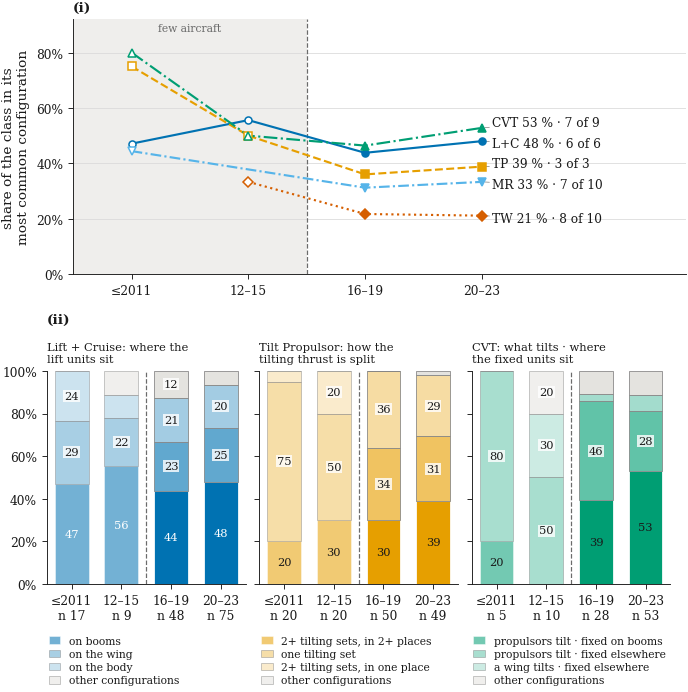

In [17]:
prop = cc[cc['rule set'] == 'proposed']
pmix = mix[mix['rule set'] == 'proposed']
share_cfg = prop.pivot(index='window', columns='code', values='share in it').reindex(COMPLETE)
poss = prop.set_index(['code', 'window'])
DISPLAY = {'SLC': lambda s: s.replace('lift units ', '', 1), 'CVT': lambda s: s.replace('rotors', 'propulsors').replace('fixed units ', 'fixed '),
           'TR': lambda s: s.replace('two or more tilting sets', '2+ tilting sets').replace('on two or more stations', 'in 2+ places').replace('on one station', 'in one place')}
CLASSES5 = ['SLC', 'TR', 'CVT', 'TW', 'MR']
fig = plt.figure(figsize=(W, 6.3), constrained_layout=True)
top, bot = fig.subfigures(2, 1, height_ratios=[1.0, 1.25])
ax = top.subplots()
plots.few_band(ax, 2)
plots.window_lines(ax, share_cfg[CLASSES5], n_few=2, ticks=[WSHORT[w] for w in COMPLETE])
ends = []
for c in CLASSES5:
    r = poss.loc[(c, '2020-23')]
    K = r['possible configurations']
    ends.append((float(r['share in it']), f"{style.cls(c).short} {100 * r['share in it']:.0f} % · {int(r['distinct configurations'])} of {int(K) if np.isfinite(K) else '–'}", style.cls(c).color))
order = sorted(range(len(ends)), key=lambda i: ends[i][0])
plots.end_labels(ax, len(COMPLETE) - 1, [ends[i][0] for i in order], [ends[i][1] for i in order], [ends[i][2] for i in order], gap=0.075)
ax.set_xlim(-0.5, len(COMPLETE) - 1 + 1.75); ax.set_ylim(0, 0.92)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0)); ax.grid(axis='y', color=style.GRID, linewidth=0.5); ax.set_axisbelow(True)
ax.set_ylabel('share of the class in its\nmost common configuration'); style.mark(ax, '(i)')
axs = bot.subplots(1, 3, sharey=True)
TITLE13 = {'SLC': 'Lift + Cruise: where the\nlift units sit', 'TR': 'Tilt Propulsor: how the\ntilting thrust is split', 'CVT': 'CVT: what tilts · where\nthe fixed units sit'}
for ax, c in zip(axs, ['SLC', 'TR', 'CVT']):
    m = pmix[pmix['code'] == c]
    lastw = m[m['window'] == '2020-23'].sort_values('aircraft', ascending=False)
    ordc = [k for k in lastw['configuration'] if not frames.cfg_outside(k)]
    keep = ordc[:3] if len(ordc) > 4 else ordc[:4]
    frac = lambda k: (m[m['configuration'].isin(k)].groupby('window')['aircraft'].sum().reindex(COMPLETE).fillna(0)
                      / m.groupby('window')['class aircraft'].first().reindex(COMPLETE))
    comp = pd.DataFrame({DISPLAY[c](k): frac([k]) for k in keep})
    rest = frac([k for k in m['configuration'].unique() if k not in keep])
    if rest.sum() > 0:
        comp['other configurations'] = rest                      # the gaps of the record and every configuration beyond the largest
    plots.config_stack(ax, comp, style.cls(c).color, n_few=2)
    nwin = m.groupby('window')['aircraft'].sum().reindex(COMPLETE)
    ax.set_xticks(range(len(COMPLETE)), [f"{WSHORT[w]}\nn {int(n)}" for w, n in zip(COMPLETE, nwin)])
    ax.set_title(TITLE13[c], fontsize=7.5, loc='left')
    ax.legend(loc='upper left', bbox_to_anchor=(-0.04, -0.2), fontsize=7, handlelength=1.1, labelspacing=0.3, frameon=False)
    if c == 'SLC':
        style.mark(ax, '(ii)', lines_up=2.3)
    else:
        ax.tick_params(labelleft=False)
plt.show()
fig13_data = pd.concat([prop.assign(panel='(i)'), pmix.assign(panel='(ii)')], ignore_index=True)
save.figure(fig, cfg, 'q3', 'fig_13_class_configurations', data=fig13_data,
            caption='how each architecture class spreads over its own configurations, per priority window: (i) the share of the class in its most common configuration; (ii) the composition of Lift + Cruise, Tilt Propulsor and CVT, the configuration that leads in 2020-23 at the bottom. Rules chosen after the shares were seen; windows before 2016 hold few aircraft.',
            source='human labelling (class; wing, boom and propulsor cards)',
            unit=f"unique aircraft of the class in the window, with a complete priority year; a window under {drivers.MIN_CELL} aircraft of the class is not drawn; the two early windows (faded) hold {int(n_win['<= 2011'])} and {int(n_win['2012-15'])} aircraft of all classes against {int(n_win['2016-19'])} and {int(n_win['2020-23'])}; the rules were chosen after the shares under earlier rules had been seen",
            read="(i) One line per class: the share of the class held by its most common configuration (the class's own rule, Method of 3.3); hollow markers and the grey band: windows with few aircraft. At the right end: the share in 2020-23 and how many of the possible configurations the class uses. (ii) The whole composition: each block is one configuration's share of the class in the window (in percent), the bottom block is the configuration that leads in 2020-23, blocks of 12 % or more print their share, and every configuration beyond the three or four largest of 2020-23 is pooled in grey. The number under each window is the class's aircraft there. Convergence is a change across windows under one rule, a share that rises toward the whole class; the level of a share is not compared between classes, because a rule with fewer possible configurations gives a larger leading share by construction.",
            panels={'(i)': 'share of each class in its most common configuration', '(ii)': 'composition of Lift + Cruise, Tilt Propulsor and CVT'})
plt.close(fig)

### 3.3 numbers

In [18]:
MIX = lambda code, w, key: float(pmix[(pmix['code'] == code) & (pmix['window'] == w) & (pmix['configuration'] == key)]['share'].sum())
MIXN = lambda code, w, key: int(pmix[(pmix['code'] == code) & (pmix['window'] == w) & (pmix['configuration'] == key)]['aircraft'].sum())
TW_ = lambda c, w: poss.loc[(c, w)]
RB, RE = 'rotors tilt · fixed units on booms', 'rotors tilt · fixed units elsewhere'
ONE, TWO_ST = 'one tilting set', 'two or more tilting sets, on two or more stations'
N3 = {'sm3b_min_cell': str(drivers.MIN_CELL), 'sm3b_cc_gaps': str(int(prop['aircraft outside the rule'].sum())),
      'sm3b_cc_slc_23': pct(TW_('SLC', '2020-23')['share in it']),
      'sm3b_cc_tr_11_k': str(int(TW_('TR', '<= 2011')['distinct configurations'])), 'sm3b_cc_tr_11_n': str(int(TW_('TR', '<= 2011')['aircraft'])),
      'sm3b_cc_tr_11_cpa': f"{TW_('TR', '<= 2011')['configurations per aircraft']:.2f}",
      'sm3b_cc_tr_23_k': str(int(TW_('TR', '2020-23')['distinct configurations'])), 'sm3b_cc_tr_23_n': str(int(TW_('TR', '2020-23')['aircraft'])),
      'sm3b_cc_tr_23_cpa': f"{TW_('TR', '2020-23')['configurations per aircraft']:.2f}",
      'sm3b_mix_cvt_rb_23': pct(MIX('CVT', '2020-23', RB)), 'sm3b_mix_cvt_re_11': pct(MIX('CVT', '<= 2011', RE)),
      'sm3b_mix_cvt_re_15': pct(MIX('CVT', '2012-15', RE)), 'sm3b_mix_cvt_re_19': pct(MIX('CVT', '2016-19', RE)),
      'sm3b_mix_tr_one_11': pct(MIX('TR', '<= 2011', ONE)), 'sm3b_mix_tr_twost_23': pct(MIX('TR', '2020-23', TWO_ST)),
      'sm3b_win_11_n': str(int(n_win['<= 2011'])), 'sm3b_win_15_n': str(int(n_win['2012-15'])),
      'sm3b_win_19_n': str(int(n_win['2016-19'])), 'sm3b_win_23_n': str(int(n_win['2020-23']))}
numbers_check(N3)
cur = cc[cc['rule set'] == 'current'].set_index(['code', 'window'])['share in it']
print('also quoted in the takeaway: SLC leader (booms) shares', [pct(TW_('SLC', w)['share in it']) for w in COMPLETE], '; SLC configurations in use', int(TW_('SLC', '2020-23')['distinct configurations']),
      'of', int(TW_('SLC', '2020-23')['possible configurations']), '; CVT 1 and 0 aircraft on booms in the two early windows:', MIXN('CVT', '<= 2011', RB), MIXN('CVT', '2012-15', RB),
      '; TR one set 2020-23', pct(MIX('TR', '2020-23', ONE)), '; TR 2016-19 aircraft (one, two+ one place, two+ two places):', MIXN('TR', '2016-19', ONE),
      MIXN('TR', '2016-19', 'two or more tilting sets, on one station'), MIXN('TR', '2016-19', TWO_ST), '; TW', pct(TW_('TW', '2020-23')['share in it']), 'MR', pct(TW_('MR', '2020-23')['share in it']),
      '; earlier rules 2011 to 2020-23: L+C', pct(cur[('SLC', '<= 2011')]), 'to', pct(cur[('SLC', '2020-23')]), ', TP', pct(cur[('TR', '<= 2011')]), 'to', pct(cur[('TR', '2020-23')]),
      ', CVT', pct(cur[('CVT', '<= 2011')]), 'to', pct(cur[('CVT', '2020-23')]))

,name,notebook,document,match
0,sm3b_min_cell,5,5,yes
1,sm3b_cc_gaps,3,3,yes
2,sm3b_cc_slc_23,48 %,48 %,yes
3,sm3b_cc_tr_11_k,3,3,yes
4,sm3b_cc_tr_11_n,20,20,yes
5,sm3b_cc_tr_11_cpa,0.15,0.15,yes
6,sm3b_cc_tr_23_k,3,3,yes
7,sm3b_cc_tr_23_n,49,49,yes
8,sm3b_cc_tr_23_cpa,0.06,0.06,yes
9,sm3b_mix_cvt_rb_23,53 %,53 %,yes


also quoted in the takeaway: SLC leader (booms) shares ['47 %', '56 %', '44 %', '48 %'] ; SLC configurations in use 6 of 6 ; CVT 1 and 0 aircraft on booms in the two early windows: 1 0 ; TR one set 2020-23 31 % ; TR 2016-19 aircraft (one, two+ one place, two+ two places): 17 18 15 ; TW 21 % MR 33 % ; earlier rules 2011 to 2020-23: L+C 53 % to 32 % , TP 65 % to 22 % , CVT 40 % to 17 %


## 3.4 — What drives the changes inside the classes?

#### Method

**Driver and trace.** A *design driver* is a cause of design change: a technology that moved, a physical limit that did not, a requirement, a cost. A driver is never written in a patent. If it acts, it leaves a **trace**: a labelled feature that moves over the years in the direction the driver predicts. The drivers considered:


| kind | drivers |
|---|---|
| A1 technological | regime transition (from hover to wing-borne flight); distributed propulsion and propulsor control |
| A2 physical | hover load path; wing structural and aeroelastic limits; cruise stability and control; flow interference and drag |
| B requirement | mission range and speed; payload; occupant presence; failure tolerance; community noise; operating environment |
| C life-cycle cost | development and certification; production; maintenance |

A physical limit (A2) does not move with the years; it predicts that two labels go together, not a trend, so an A2 driver never makes a trace rise or fall.

**What a trace is.** One label read against the priority year: a **share** of the aircraft (propulsor units on booms, a ducted propulsor unit) or a **count per aircraft**. Three counts carry this section; all are defined in the propulsion vocabulary at the head of chapter 2:

- *propulsor units*: the propulsors, propellers and fans that give lift or thrust;
- *propulsor types*: sets of like propulsor units in one place: a Lift + Cruise with lift propulsors on booms and a pusher on the fuselage has two; a tilt propulsor that adds a tilting set on its tail goes from one to two;
- *tilting sets*: the parts that swivel their propulsor units between hover and cruise as one: a tilting propulsor type, a tilting wing panel, a tilting boom group or a tilting tail each count one.

**Read inside each class, never pooled.** *Pooled* means every class thrown into one curve. A pooled curve mixes two movements: change *inside* designs, and change in *which* designs are filed. Tilting sets show the difference. Inside Tilt Propulsor they rise, from 1.4 to 1.8 per aircraft on average (p 0.010), and they rise inside CVT too. Over the same windows Tilt Propulsor falls from 32 % to 21 % of all aircraft, while Lift + Cruise, which has no tilting set, rises from 27 % to 32 %. Pooled, the aircraft with many tilting sets become fewer and those with none become more, so the pooled curve stays flat (0.7 to 0.9, p 0.822) although the sets rose inside both tilting classes. Reading each class on its own removes that mixing: a class's curve moves only when its own aircraft change. A driver acts on how an aircraft is built, so it is looked for one class at a time; a pooled row is printed only as this contrast.

**The test.** Spearman ρ between each aircraft's own priority year and the trace, over every aircraft of the class with a value and a priority year up to 2023: *rises* or *falls* at p < 0.05, *flat* (no trend detected) otherwise; read on 20 aircraft or more (statistics box).

**The years read.** The figures group the years in four-year windows; the two early windows hold 63 and 58 aircraft against 213 and 237 in the two after, so they are drawn faded behind a vertical line and labelled *few aircraft*, and no figure is read on them. The test does not use windows: it runs on every year, so an early aircraft counts once, like any other. A window is drawn only with 5 aircraft of the class or more.

**The centre: mean or median.** The median is used where a few extreme aircraft would carry a mean: propulsor units, where a handful of hull arrays carry tens of propulsor units. The mean is used for small whole-number counts (tilting sets, propulsor types) and for tilting sets per unit, because a median of 1 or 2 (or of ½) stands still while the mix of aircraft moves under it. A share is a share of the aircraft that answer the label.

**What is shown.**

- **Figure 14**: the move of the tilting classes. *(i)* each class's centre per window, mean tilting sets against median propulsor units, joined by arrows (Lift + Cruise, Tilt Propulsor, CVT: the three largest classes, and the two that tilt); *(ii)* Tilt Propulsor, median propulsor units by the number of tilting sets, all years; *(iii)* CVT, the share of its aircraft with propulsor units on booms; *(iv)* CVT, the share with a ducted propulsor unit inside each boom layout, one line for the aircraft with propulsor units on booms and one for those without, each with its own trend test; each point is labelled with the layout's aircraft over all CVT of the window (layout / all), and a share is drawn only when the layout holds 5 aircraft or more of that window; *(v)* tilting sets per propulsor unit, with its test.
- **Figure 15**: two traces in every class: propulsor units carried on booms, and a ducted propulsor unit.
- **Table 9**: every trace that moves in at least one class: where it moved, with ρ and p, and the drivers it goes **with** (it moved the way they predict) and **against** (it moved the other way). *Overdetermined:* several drivers predict the same move, and the labelled dataset cannot say which. ●: the traces this section reads.

*Unit:* the unique aircraft, because a trace is a property of a design, and a design filed five times is still one design. *What a trace can say:* a move in the predicted direction is *consistent* with its driver; it does not prove it. Source: human labelling (class; wing, boom and propulsor cards).

### The traces, per class and over the priority years

`frames.trace_frame` reads every labelled trace of an aircraft (tilting sets, propulsor units, propulsor types, units on booms, a ducted unit, …). `lib.drivers.trace_drift` gives the share or the median per class and window, `lib.drivers.trace_trends` the Spearman test of the trace against each aircraft's own priority year (every year up to 2023, 20 aircraft or more, p < 0.05), inside each class and, as a contrast only, pooled over the five classes. The classes read are those with 5 aircraft or more in at least three windows (`lib.drivers.class_selection`). The trends are checked against the document's `la_trace_trends`.

In [19]:
tf = frames.trace_frame(ds, v)
classes = drivers.class_selection(v)                      # SLC, TR, CVT, TW, MR: largest first
drift = drivers.trace_drift(tf, classes, class_names=CLASS_NAMES)
trends = drivers.trace_trends(tf, drift, classes, class_names=CLASS_NAMES)
verify(trends, 'la_trace_trends', key=['trace', 'code'])
trend = lambda trace, code: trends[(trends['trace'] == trace) & (trends['code'] == code)].iloc[0]
trends[trends['code'].isin(['TR', 'CVT', 'ALL5']) & trends['trace'].isin(['tilting joint groups', 'propulsive units', 'units carried on booms'])][
    ['trace', 'code', 'aircraft', 'first window', 'first value', '2020-23 value', 'first mean', '2020-23 mean', 'rho', 'p', 'movement']]

,la_trace_trends
table,la_trace_trends
rows (notebook | document),119 | 119
cells compared,1309
matched,1309
expected differences,0
differences,0
status,match


,trace,code,aircraft,first window,first value,2020-23 value,first mean,2020-23 mean,rho,p,movement
1,tilting joint groups,TR,139,<= 2011,1.00,2.00,1.35,1.76,0.22,1.033356e-02,rises
2,tilting joint groups,CVT,96,<= 2011,1.00,1.00,1.00,1.43,0.25,1.346554e-02,rises
5,tilting joint groups,ALL5,480,<= 2011,1.00,1.00,0.73,0.92,0.01,8.219811e-01,flat
29,propulsive units,TR,139,<= 2011,2.00,4.00,NaN,NaN,0.41,6.491239e-07,rises
30,propulsive units,CVT,96,<= 2011,4.00,6.00,NaN,NaN,0.31,2.110341e-03,rises
33,propulsive units,ALL5,480,<= 2011,4.00,6.00,NaN,NaN,0.25,3.574152e-08,rises
36,units carried on booms,TR,139,<= 2011,0.20,0.39,NaN,NaN,0.11,1.907797e-01,flat
37,units carried on booms,CVT,96,<= 2011,0.20,0.62,NaN,NaN,0.22,3.295594e-02,rises
40,units carried on booms,ALL5,480,<= 2011,0.25,0.51,NaN,NaN,0.17,1.622596e-04,rises


### The windowed centres, the two links and the sets per propulsor unit

`lib.drivers.driver_windows`: per class and complete window, the centre of each trace drawn (propulsor units as a median, tilting sets and propulsor types as a mean, shares as shares of the aircraft that answer; blank under 5 values). `lib.drivers.driver_links`: Tilt Propulsor's propulsor units by tilting sets, and CVT's ducted share inside each boom layout with its own trend test. `frames.sets_per_unit_brief`: tilting sets per aircraft and per propulsor unit. All three are checked against the document.

In [20]:
dw = drivers.driver_windows(cf, CLASSES5, COMPLETE, FEW, class_names=CLASS_NAMES)
links = drivers.driver_links(cf)
spu = frames.sets_per_unit_brief(cf, COMPLETE, WSHORT)
verify(dw, 'la_driver_windows', key=['code', 'window'])
verify(links, 'la_driver_links', key=['link', 'group'])
verify(spu, 'la_sets_per_unit_brief', key=['code', 'measure'], doc_wording=False)
dw[['code', 'window', 'aircraft', 'tilting sets (mean)', 'propulsive units (median)', 'share with units on booms', 'share with a ducted unit']]

,la_driver_windows
table,la_driver_windows
rows (notebook | document),20 | 20
cells compared,340
matched,340
expected differences,0
differences,0
status,match


,la_driver_links
table,la_driver_links
rows (notebook | document),6 | 6
cells compared,36
matched,36
expected differences,0
differences,0
status,match


,la_sets_per_unit_brief
table,la_sets_per_unit_brief
rows (notebook | document),6 | 6
cells compared,54
matched,54
expected differences,0
differences,0
status,match


,code,window,aircraft,tilting sets (mean),propulsive units (median),share with units on booms,share with a ducted unit
0,SLC,<= 2011,17,0.000,10.0,0.471,0.529
1,SLC,2012-15,9,0.000,5.0,0.667,0.222
2,SLC,2016-19,48,0.000,6.5,0.521,0.292
3,SLC,2020-23,75,0.000,7.0,0.560,0.480
4,TR,<= 2011,20,1.350,2.0,0.200,0.150
5,TR,2012-15,20,1.650,2.0,0.300,0.450
6,TR,2016-19,50,1.800,4.0,0.400,0.420
7,TR,2020-23,49,1.755,4.0,0.388,0.306
8,CVT,<= 2011,5,1.000,4.0,0.200,0.800
9,CVT,2012-15,10,1.100,4.0,0.200,0.400


### Figure 14 — the move of the tilting classes

(i) Each class's centre per window, mean tilting sets against median propulsor units, joined by arrows in time order (hollow, faint: windows with few aircraft). (ii) Tilt Propulsor: median propulsor units by the number of tilting sets. (iii) CVT: the share with propulsor units on booms. (iv) CVT: the share with a ducted propulsor unit inside each boom layout, labelled with the layout's aircraft over all CVT of the window. (v) Tilting sets per propulsor unit, mean, with its trend test.

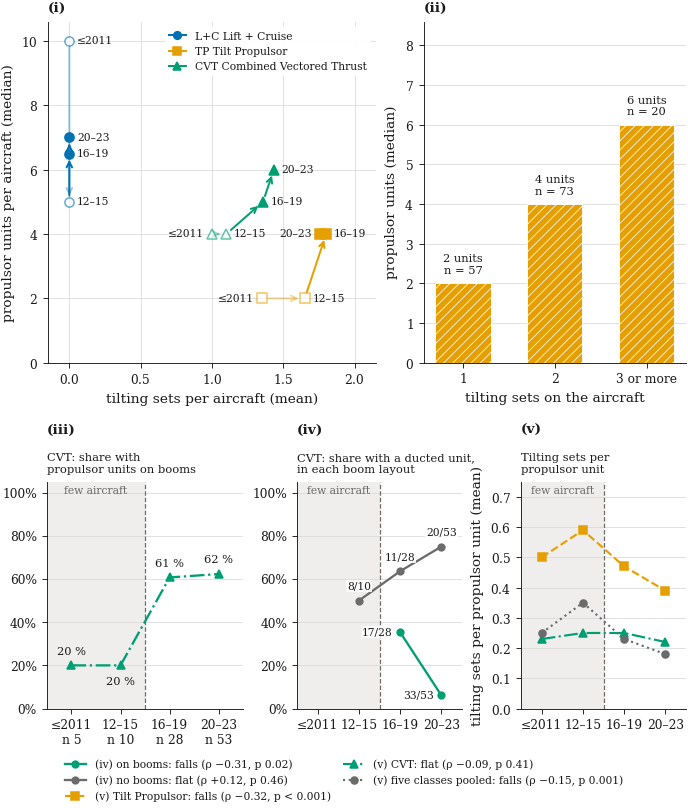

In [21]:
tw = lambda c: dw[dw['code'] == c].set_index('window').reindex(COMPLETE)
test_txt = lambda r: f"{r['movement']} (ρ {r['rho']:+.2f}, {ptxt(r['p'])})".replace('-', '−')
fig = plt.figure(figsize=(W, 7.4), constrained_layout=True)
top, bot = fig.subfigures(2, 1, height_ratios=[1.0, 0.95])
a1, a2 = top.subplots(1, 2, gridspec_kw={'width_ratios': [1.25, 1.0]})
# (i) the centres
cent = {c: pd.DataFrame({'x': tw(c)['tilting sets (mean)'], 'y': tw(c)['propulsive units (median)']}) for c in ('SLC', 'TR', 'CVT')}
pts = plots.centre_trajectory(a1, cent, n_few=2)
a1.set_xlim(-0.15, 2.15); a1.set_ylim(0, 10.6)
a1.set_xlabel('tilting sets per aircraft (mean)'); a1.set_ylabel('propulsor units per aircraft (median)')
a1.grid(color=style.GRID, linewidth=0.5); a1.set_axisbelow(True); style.mark(a1, '(i)')
leg = a1.legend(handles=[Line2D([], [], color=style.cls(c).color, marker=style.cls(c).marker, markersize=5, linewidth=1.3, label=f"{style.cls(c).short} {style.cls(c).name}") for c in ('SLC', 'TR', 'CVT')],
                loc='upper right', fontsize=7, frameon=True, framealpha=0.95, edgecolor='none', handlelength=1.6)
# (ii) Tilt Propulsor: units by tilting sets
lk = links[links['link'].str.startswith('Tilt Rotor')]
s = style.cls('TR')
a2.bar(range(len(lk)), lk['median'], width=0.6, color=s.color, hatch=s.hatch, edgecolor='white', linewidth=0.6, zorder=3)
for i, (m, n) in enumerate(zip(lk['median'], lk['aircraft'])):
    a2.text(i, m + 0.2, f"{m:g} units\nn = {int(n)}", ha='center', va='bottom', fontsize=7.5)
a2.set_xticks(range(len(lk)), list(lk['group'].astype(str))); a2.set_ylim(0, float(lk['median'].max()) + 2.6)
a2.set_xlabel('tilting sets on the aircraft'); a2.set_ylabel('propulsor units (median)')
a2.grid(axis='y', color=style.GRID, linewidth=0.5); a2.set_axisbelow(True); style.mark(a2, '(ii)')
# (iii)-(v)
b3, b4, b5 = bot.subplots(1, 3, gridspec_kw={'width_ratios': [1.25, 1.05, 1.05]})
x = np.arange(len(COMPLETE)); cv = tw('CVT'); sc = style.cls('CVT')
nb, nn = cv['aircraft, units on booms'].to_numpy(), cv['aircraft, no units on booms'].to_numpy()
pc = lambda a: a.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
plots.few_band(b3, 2); y3 = cv['share with units on booms'].to_numpy(dtype=float)
b3.plot(x, y3, color=sc.color, linestyle=sc.dash, linewidth=1.5, marker=sc.marker, markersize=4.6, zorder=3)
for xi in x:
    dip = 0 < xi < len(y3) - 1 and y3[xi] <= min(y3[xi - 1], y3[xi + 1])
    b3.annotate(f"{100 * y3[xi]:.0f} %", (xi, y3[xi]), textcoords='offset points', xytext=(0, -7 if dip else 6), ha='center', va='top' if dip else 'bottom', fontsize=7.5, color=style.INK)
b3.set_xticks(x, [f"{WSHORT[w]}\nn {int(a + b)}" for w, a, b in zip(COMPLETE, nb, nn)]); b3.set_ylim(0, 1.05); pc(b3)
b3.set_xlim(-0.5, len(x) - 0.5); b3.grid(axis='y', color=style.GRID, linewidth=0.5); b3.set_axisbelow(True); style.mark(b3, '(iii)', lines_up=2.3)
b3.set_title('CVT: share with\npropulsor units on booms', fontsize=7.5, loc='left')
plots.few_band(b4, 2)
lt = links[links['link'].str.startswith('CVT')].set_index('group')
for name, col, c, ns, txt in (('units on booms', 'ducted share, units on booms', sc.color, nb, 'on booms'), ('no units on booms', 'ducted share, no units on booms', style.MUTED, nn, 'no booms')):
    y = cv[col].to_numpy(dtype=float); ok = np.isfinite(y)
    b4.plot(x[ok], y[ok], color=c, linewidth=1.5, marker='o', markersize=4.4, zorder=3, label=f"(iv) {txt}: {test_txt(lt.loc[name])}")
    for xi in x[ok]:
        below = name.startswith('units')
        b4.annotate(f"{int(ns[xi])}/{int(nb[xi] + nn[xi])}", (xi, y[xi]), textcoords='offset points', xytext=(-5, 0) if below else (0, 6), ha='right' if below else 'center',
                    va='center' if below else 'bottom', fontsize=7, color=style.INK, bbox=dict(fc='white', ec='none', pad=0.6, alpha=0.85))
b4.set_xticks(x, [WSHORT[w] for w in COMPLETE]); b4.set_ylim(0, 1.05); b4.set_xlim(-0.5, len(x) - 0.5); pc(b4)
b4.grid(axis='y', color=style.GRID, linewidth=0.5); b4.set_axisbelow(True); style.mark(b4, '(iv)', lines_up=2.3)
b4.set_title('CVT: share with a ducted unit,\nin each boom layout', fontsize=7.5, loc='left')
plots.few_band(b5, 2)
su = spu[spu['measure'] == 'tilting sets per propulsive unit'].set_index('code')
for code, lbl in (('TR', 'Tilt Propulsor'), ('CVT', 'CVT'), ('ALL5', 'five classes pooled')):
    r = su.loc[code]; y = np.array([r[WSHORT[w]] for w in COMPLETE], dtype=float); ok = np.isfinite(y)
    if code == 'ALL5':
        kw = dict(color=style.MUTED, linestyle=':', marker='o')
    else:
        st_ = style.cls(code); kw = dict(color=st_.color, linestyle=st_.dash, marker=st_.marker)
    b5.plot(x[ok], y[ok], linewidth=1.4, markersize=4.6, zorder=3, label=f"(v) {lbl}: {test_txt(r)}", **kw)
b5.set_xticks(x, [WSHORT[w] for w in COMPLETE]); b5.set_ylim(0, 0.75); b5.set_xlim(-0.5, len(x) - 0.5)
b5.grid(axis='y', color=style.GRID, linewidth=0.5); b5.set_axisbelow(True); b5.set_ylabel('tilting sets per propulsor unit (mean)')
style.mark(b5, '(v)', lines_up=2.3)
b5.set_title('Tilting sets per\npropulsor unit', fontsize=7.5, loc='left')
hh, ll = b4.get_legend_handles_labels(); h5, l5 = b5.get_legend_handles_labels()
bot.legend(hh + h5, ll + l5, loc='outside lower center', ncol=2, fontsize=7, handlelength=2.0, columnspacing=1.2)
fig.canvas.draw()
rend = fig.canvas.get_renderer()
lab = [WSHORT[COMPLETE[k]] for _, _, k, _ in pts]
failed = plots.place_labels(a1, [p[0] for p in pts], [p[1] for p in pts], lab, [3.6] * len(pts), obstacles=[leg.get_window_extent(rend).expanded(1.03, 1.1)], fontsize=7)
assert not failed, failed
plt.show()
fig14_data = pd.concat([dw.assign(panel='(i), (iii), (iv)'), links.assign(panel='(ii), (iv)'), spu.assign(panel='(v)')], ignore_index=True)
save.figure(fig, cfg, 'q3', 'fig_14_tilting_classes_move', data=fig14_data,
            caption="the move of the tilting classes: (i) each class's centre per window in tilting sets and propulsor units; (ii) Tilt Propulsor's propulsor units by tilting sets; (iii) the share of CVT with propulsor units on booms; (iv) the share of CVT with a ducted propulsor unit, one line per boom layout, each named at its end; (v) tilting sets per propulsor unit.",
            source='human labelling (class; wing, boom and propulsor cards)',
            unit=f"unique aircraft of the class in the window (5 or more), complete priority years; (ii) the {int(lk['aircraft'].sum())} Tilt Propulsor aircraft with a unit count, all years; (v) aircraft of the class with a unit count; trend tests on every year up to 2023",
            read="(i) Each point is a class's centre in one window (hollow and faint: windows with few aircraft); arrows join the windows in time order; right means more tilting sets per aircraft, up more propulsor units. (ii) Bar: the median propulsor units of the Tilt Propulsor aircraft with one, two, and three or more tilting sets; above it its aircraft. (iii) Share of CVT aircraft that carry propulsor units on booms. (iv) Share of CVT with a ducted propulsor unit, one line for the aircraft with propulsor units on booms and one for those without, each with its Spearman trend against the priority year (every year to 2023); a point is labelled with the layout's aircraft over all CVT of the window, and a share is drawn only when the layout holds 5 aircraft or more of that window. (v) Tilting sets per propulsor unit, mean per window, with the trend test of each line.",
            panels={'(i)': "each class's centre per window", '(ii)': 'Tilt Propulsor: propulsor units by tilting sets', '(iii)': 'CVT: share with units on booms',
                    '(iv)': 'CVT: ducted share inside each boom layout', '(v)': 'tilting sets per propulsor unit'})
plt.close(fig)

### Figure 15 — two traces per class and window

(i) The share of each class's aircraft that carry propulsor units on booms; (ii) the share with a ducted propulsor unit. A point needs 5 aircraft of the class in the window.

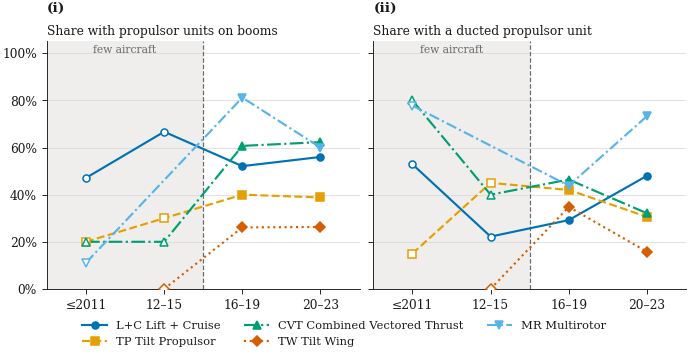

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(W, 3.3), constrained_layout=True, sharey=True)
for ax, col, mk in zip(axs, ('share with units on booms', 'share with a ducted unit'), ('(i)', '(ii)')):
    plots.few_band(ax, 2)
    fr = dw.pivot(index='window', columns='code', values=col).reindex(COMPLETE)[CLASSES5]
    plots.window_lines(ax, fr, n_few=2, ticks=[WSHORT[w] for w in COMPLETE])
    ax.set_xlim(-0.5, len(COMPLETE) - 0.5); ax.set_ylim(0, 1.05); ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
    ax.grid(axis='y', color=style.GRID, linewidth=0.5); ax.set_axisbelow(True); style.mark(ax, mk, lines_up=1.2)
axs[0].set_title('Share with propulsor units on booms', fontsize=8, loc='left', pad=4); axs[1].set_title('Share with a ducted propulsor unit', fontsize=8, loc='left', pad=4)
fig.legend(handles=[Line2D([], [], color=style.cls(c).color, linestyle=style.cls(c).dash, marker=style.cls(c).marker, markersize=4.6, linewidth=1.4,
                           label=f"{style.cls(c).short} {style.cls(c).name}") for c in CLASSES5], loc='outside lower center', ncol=3, fontsize=7.5, handlelength=2.2)
plt.show()
save.figure(fig, cfg, 'q3', 'fig_15_boom_duct_traces', data=dw[['class', 'code', 'window', 'aircraft', 'share with units on booms', 'share with a ducted unit']],
            caption='two traces per architecture class and priority window: (i) the share of aircraft that carry propulsor units on booms; (ii) the share with a ducted propulsor unit.',
            source='human labelling (class; propulsor cards: the places carrying propulsor units, the ducted flag)',
            unit='unique aircraft of the class in the window (5 or more); the two early windows (faded) hold few aircraft',
            read='One line per class, in the class\'s colour, dash and marker; hollow markers and the grey band: windows with few aircraft (63 and 58 aircraft of all classes against 213 and 237 in the two after). (i) The share of the class\'s aircraft that carry propulsor units on booms. (ii) The share with at least one ducted propulsor unit. A window with fewer than 5 aircraft of the class is not drawn.',
            panels={'(i)': 'share of aircraft with propulsor units on booms', '(ii)': 'share of aircraft with a ducted propulsor unit'})
plt.close(fig)

### Table 9 — the traces that move, and the drivers they go with and against

`lib.drivers.driver_verdicts` codes, per trace, the direction it moved (a class that rises or falls counts; the pooled row counts; mixed when classes move both ways) and the verdict from the drivers that predict it (`lib.drivers.driver_verdict`: a fixed physical driver, A2, never makes a trace rise or fall). The table prints the traces that move in at least one class or pooled: where each moved (every year to 2023), the drivers it goes with (it moved the way they predict) and against, and what it means. The raw verdicts are checked against the document's `la_driver_verdicts`, the printed table against the document's Table 9 as printed.

In [23]:
verd = drivers.driver_verdicts(trends)
CODE_TEXT = {'does_not_move': 'trace does not move', 'mixed_by_class': 'mixed by class', 'fixed_only': 'moves, but only fixed physical drivers predict this trace',
             'opposed': 'opposed drivers', 'single': 'single driver', 'against_all': 'moved against every driver that predicts a direction',
             'overdetermined': 'overdetermined', 'not_labelled': 'not labelled'}
raw_verdicts = pd.DataFrame({'trace': [t['label'] + ('' if t['kind'] == 'share' else ' (median)') for t in drivers.TRACES] + [u[0] for u in drivers.UNLABELLED_TRACES],
                             'driver kind': verd['driver kind'], 'verdict class': verd['verdict'].map(CODE_TEXT)})
verify(raw_verdicts, 'la_driver_verdicts', key=['trace'], columns=['trace', 'driver kind', 'verdict class'], doc_wording=False)

,la_driver_verdicts
table,la_driver_verdicts
rows (notebook | document),22 | 22
cells compared,44
matched,44
expected differences,0
differences,0
status,match


In [24]:
CLASS_WORD = {'SLC': 'Lift + Cruise', 'TR': 'Tilt Propulsor', 'CVT': 'CVT', 'TW': 'Tilt Wing', 'MR': 'Multirotor'}
TRACE_WORD = {'joints': 'tilting sets per aircraft', 'fus_moves': 'a body that tilts or rotates', 'units': 'propulsor units per aircraft',
              'on_booms': 'propulsor units carried on booms', 'stations': 'places carrying propulsor units per aircraft', 'booms': 'booms present',
              'pusher': 'a pusher unit', 'two_wings': 'two or more wing panels', 'tailless': 'no tail surface', 'gear_drawn': 'landing gear drawn',
              'n_types': 'propulsor types per aircraft'}
READ_HERE = {'joints', 'units', 'on_booms', 'ducted', 'n_types'}                      # the traces 3.4 reads: marked ●
READING = {'opposed': 'drivers disagree; it moved with those under *goes with*', 'overdetermined': '{n} drivers predict it; the labelled dataset cannot say which acts',
           'single': 'one driver predicts it, and it moved that way', 'against_all': 'moved against the only direction any driver predicts',
           'fixed_only': 'no driver predicts a direction; only physical limits bear on it', 'mixed_by_class': 'classes move in opposite directions; no driver reading'}
READING_EXTRA = {'joints': '; per propulsor unit it falls (trajectory figure, v)', 'ducted': '; in CVT it follows the boom layout (trajectory figure, iv)',
                 'n_types': '; in Tilt Propulsor the added type is a second tilting set'}
dname = lambda c: drivers.DRIVERS[c][1].replace('rotor control', 'propulsor control')
rows = []
for tr, vr in zip(drivers.TRACES, verd.iloc[:len(drivers.TRACES)].itertuples()):
    t = trends[trends['trace'] == tr['label']].set_index('code')
    moved = [c for c in classes if t.loc[c, 'movement'] in ('rises', 'falls')]
    if not moved and t.loc['ALL5', 'movement'] not in ('rises', 'falls'):
        continue                                                       # the trace does not move anywhere: not printed
    parts = [f"{t.loc[c, 'movement']} in {CLASS_WORD[c]} (ρ {t.loc[c, 'rho']:+.2f}, {ptxt(t.loc[c, 'p'])})" for c in moved]
    where = ('; '.join(parts) if parts else 'no trend detected in any class') + f"; pooled: {t.loc['ALL5', 'movement']}"
    inside = {t.loc[c, 'movement'] for c in moved}
    d = '+' if inside == {'rises'} else '-' if inside == {'falls'} else 'mixed'          # inside the classes only; a pooled move alone is 'mixed'
    with_, against = [], []
    for code_, sign in tr['drivers'].items():
        if sign in '+-' and d != 'mixed':
            (with_ if sign == d else against).append(f"{dname(code_)} ({'more' if sign == '+' else 'fewer'})")
    meaning = READING[vr.verdict].format(n=len(tr['drivers'])) + READING_EXTRA.get(tr['key'], '')
    if vr.verdict == 'fixed_only':
        meaning += ' (' + ', '.join(dname(c) for c in tr['drivers']) + ')'
    rows.append({'trace': ('● ' if tr['key'] in READ_HERE else '') + TRACE_WORD.get(tr['key'], tr['label']), 'where it moved (every year to 2023)': where,
                 'goes with (driver: what it predicts)': '; '.join(with_) or '—', 'goes against (driver: what it predicts)': '; '.join(against) or '—',
                 'what it means': meaning})
t9 = pd.DataFrame(rows)
doc9 = checks.brief_table(cfg, 9)
verify(t9, None, 'Table 9 as printed in the document', doc_wording=False, key=['trace'], ref_frame=doc9)
save.table(t9, cfg, 'q3', 'tab_9_driver_verdicts', caption='The traces that move inside at least one class: where each moved, and the drivers it goes with and against.', source='human labelling (class; wing, boom and propulsor cards) · Spearman rank correlation against the priority year, every year to 2023')
t9

,Table 9 as printed in the document
table,Table 9 as printed in the document
rows (notebook | document),11 | 11
cells compared,44
matched,44
expected differences,0
differences,0
status,match


,trace,where it moved (every year to 2023),goes with (driver: what it predicts),goes against (driver: what it predicts),what it means
0,● tilting sets per aircraft,"rises in Tilt Propulsor (ρ +0.22, p 0.01); rises in CVT (ρ +0.25, p 0.01); pooled: flat",regime transition (more),development and certification cost (fewer); maintenance cost (fewer),"drivers disagree; it moved with those under *goes with*; per propulsor unit it falls (trajectory figure, v)"
1,a body that tilts or rotates,"falls in Multirotor (ρ -0.37, p 0.01); pooled: falls",occupant presence (fewer),regime transition (more),drivers disagree; it moved with those under *goes with*
2,● propulsor units per aircraft,"rises in Tilt Propulsor (ρ +0.41, p < 0.001); rises in CVT (ρ +0.31, p 0.002); pooled: rises",distributed propulsion and propulsor control (more); failure tolerance (more); community noise (more),—,3 drivers predict it; the labelled dataset cannot say which acts
3,● propulsor units carried on booms,"rises in CVT (ρ +0.22, p 0.03); rises in Tilt Wing (ρ +0.29, p 0.04); pooled: rises",distributed propulsion and propulsor control (more),—,"one driver predicts it, and it moved that way"
4,places carrying propulsor units per aircraft,"rises in Tilt Propulsor (ρ +0.19, p 0.03); pooled: rises",distributed propulsion and propulsor control (more),—,"one driver predicts it, and it moved that way"
5,booms present,no trend detected in any class; pooled: rises,—,—,"no driver predicts a direction; only physical limits bear on it (hover load path, flow interference and drag)"
6,a pusher unit,no trend detected in any class; pooled: rises,—,—,no driver predicts a direction; only physical limits bear on it (flow interference and drag)
7,two or more wing panels,no trend detected in any class; pooled: rises,—,—,"one driver predicts it, and it moved that way"
8,no tail surface,"falls in CVT (ρ -0.30, p 0.003); pooled: flat",—,—,no driver predicts a direction; only physical limits bear on it (cruise stability and control)
9,landing gear drawn,"rises in Multirotor (ρ +0.38, p 0.01); pooled: rises",—,—,3 drivers predict it; the labelled dataset cannot say which acts


### 3.4 numbers

In [25]:
fw = lambda r: f"{r:.1f}"
words5 = {1: 'one', 2: 'two', 3: 'three', 4: 'four', 5: 'five', 6: 'six'}
from fractions import Fraction
def frac_words(x, long=False):
    f = Fraction(x).limit_denominator(5)
    a, b = words5.get(f.numerator, str(f.numerator)), words5.get(f.denominator, str(f.denominator))
    return f"{a} tilting {'set' if f.numerator == 1 else 'sets'} for every {b} propulsor units" if long else f"{a} for every {b}"
pt = lambda p: '< 0.001' if p < 0.001 else f"{p:.3f}" if p < 0.01 else f"{p:.2f}"
jt, jall = trend('tilting joint groups', 'TR'), trend('tilting joint groups', 'ALL5')
onb_cvt, onb_slc = trend('units carried on booms', 'CVT'), trend('units carried on booms', 'SLC')
duc_cvt, duc_slc = trend('a ducted unit', 'CVT'), trend('a ducted unit', 'SLC')
sp = spu.set_index(['code', 'measure'])
sp_unit = lambda c, w: float(sp.loc[(c, 'tilting sets per propulsive unit'), WSHORT[w]])
dwi = dw.set_index(['code', 'window'])
span = f"{pct(duc_cvt['first value'])} to {pct(duc_cvt['2020-23 value'])}"
below = f", to below Lift + Cruise's {pct(duc_slc['2020-23 value'])}"
duct_answer = (f"CVT also sheds its ducts ({span}){below}." if duc_cvt['movement'] == 'falls' else
               f"CVT's share with a ducted unit also drops ({span}){below}, though as a year trend this is not detected (p {pt(duc_cvt['p'])}).")
N4 = {'sm3b_trend_min': str(cfg.analysis['trend_min_n']),
      'sm3b_dw_cvt_11_n': str(int(dwi.loc[('CVT', '<= 2011'), 'aircraft'])), 'sm3b_dw_cvt_11_nb': str(int(dwi.loc[('CVT', '<= 2011'), 'aircraft, units on booms'])),
      'sm3b_dw_cvt_23_n': str(int(dwi.loc[('CVT', '2020-23'), 'aircraft'])), 'sm3b_dw_cvt_23_nb': str(int(dwi.loc[('CVT', '2020-23'), 'aircraft, units on booms'])),
      'sm3b_dw_tr_11_units': f"{dwi.loc[('TR', '<= 2011'), 'propulsive units (median)']:g}", 'sm3b_dw_tr_23_units': f"{dwi.loc[('TR', '2020-23'), 'propulsive units (median)']:g}",
      'sm3b_t_onb_cvt_first': pct(onb_cvt['first value']), 'sm3b_t_onb_cvt_last': pct(onb_cvt['2020-23 value']), 'sm3b_t_onb_cvt_p': pt(onb_cvt['p']),
      'sm3b_t_onb_slc_last': pct(onb_slc['2020-23 value']),
      'sm3b_spu_tr_unit_11': f"{sp_unit('TR', '<= 2011'):.2f}", 'sm3b_spu_tr_unit_23': f"{sp_unit('TR', '2020-23'):.2f}",
      'sm3b_spu_tr_unit_11_frac_long': frac_words(sp_unit('TR', '<= 2011'), long=True), 'sm3b_spu_tr_unit_23_frac': frac_words(sp_unit('TR', '2020-23')),
      'sm3b_duct_answer': duct_answer,
      'sm_t_joints_tr_first': fw(jt['first mean']), 'sm_t_joints_tr_last': fw(jt['2020-23 mean']), 'sm_t_joints_tr_p': pval3(jt['p']),
      'sm_t_joints_all_first': fw(jall['first mean']), 'sm_t_joints_all_last': fw(jall['2020-23 mean']), 'sm_t_joints_all_p': pval3(jall['p'])}
# the document prints the old names in this one sentence-valued number (the display rename of 2026-09-28 came after): compare in its words
N4 = {k: (checks.doc_wording(v_) if k == 'sm3b_duct_answer' else v_) for k, v_ in N4.items()}
numbers_check(N4)

,name,notebook,document,match
0,sm3b_trend_min,20,20,yes
1,sm3b_dw_cvt_11_n,5,5,yes
2,sm3b_dw_cvt_11_nb,1,1,yes
3,sm3b_dw_cvt_23_n,53,53,yes
4,sm3b_dw_cvt_23_nb,33,33,yes
5,sm3b_dw_tr_11_units,2,2,yes
6,sm3b_dw_tr_23_units,4,4,yes
7,sm3b_t_onb_cvt_first,20 %,20 %,yes
8,sm3b_t_onb_cvt_last,62 %,62 %,yes
9,sm3b_t_onb_cvt_p,0.03,0.03,yes


In [26]:
# also quoted in the takeaways of 3.4 (not in the document's number list): each against the figure the document prints
tc = lambda code, w, col: dwi.loc[(code, w), col]
tt_ = lambda trace, code: trend(trace, code)
moving_inside = sum(1 for tr in drivers.TRACES if any(trend(tr['label'], c)['movement'] in ('rises', 'falls') for c in classes))
EXTRA4 = {
    'TR sets 11 / 23': (f"{fw(tc('TR', '<= 2011', 'tilting sets (mean)'))} / {fw(tc('TR', '2020-23', 'tilting sets (mean)'))}", '1.4 / 1.8'),
    'CVT sets 11 / 23 and units': (f"{fw(tc('CVT', '<= 2011', 'tilting sets (mean)'))} / {fw(tc('CVT', '2020-23', 'tilting sets (mean)'))}; {tc('CVT', '<= 2011', 'propulsive units (median)'):g} / {tc('CVT', '2020-23', 'propulsive units (median)'):g}", '1.0 / 1.4; 4 / 6'),
    'units rho TR, CVT': (f"{tt_('propulsive units', 'TR')['rho']:+.2f} / {tt_('propulsive units', 'CVT')['rho']:+.2f}", '+0.41 / +0.31'),
    'units p TR, CVT': (f"{ptxt(tt_('propulsive units', 'TR')['p'])} / {ptxt(tt_('propulsive units', 'CVT')['p'])}", 'p < 0.001 / p 0.002'),
    'sets rho TR, CVT': (f"{tt_('tilting joint groups', 'TR')['rho']:+.2f} / {tt_('tilting joint groups', 'CVT')['rho']:+.2f}", '+0.22 / +0.25'),
    'TR median units by sets': (' / '.join(f"{m:g}" for m in lk['median']), '2 / 4 / 6'),
    'TR two or more sets 2020-23, any fixed unit': (f"{pct(tc('TR', '2020-23', 'share with two or more tilting sets'))} / {pct(tc('TR', '2020-23', 'share with a fixed unit'))}", '67 % / 2 %'),
    'CVT no booms ducted 2016-19, 2020-23': (f"{pct(tc('CVT', '2016-19', 'ducted share, no units on booms'))} / {pct(tc('CVT', '2020-23', 'ducted share, no units on booms'))}", '64 % / 75 %'),
    'CVT booms ducted 2016-19, 2020-23': (f"{pct(tc('CVT', '2016-19', 'ducted share, units on booms'))} / {pct1(tc('CVT', '2020-23', 'ducted share, units on booms'))}", '35 % / 6.1 %'),
    'CVT booms ducted trend': (f"{lt.loc['units on booms', 'rho']:+.2f}, {ptxt(lt.loc['units on booms', 'p'])}", '-0.31, p 0.02'),
    'CVT no booms trend': (f"{lt.loc['no units on booms', 'movement']}", 'flat'),
    'CVT duct 80 to 32, rho p': (f"{pct(duc_cvt['first value'])} to {pct(duc_cvt['2020-23 value'])}; {duc_cvt['rho']:+.2f}, {ptxt(duc_cvt['p'])}", '80 % to 32 %; -0.20, p 0.05'),
    'TR sets per aircraft rho p': (f"{sp.loc[('TR', 'tilting sets per aircraft'), 'rho']:+.2f}, {ptxt(sp.loc[('TR', 'tilting sets per aircraft'), 'p'])}", '+0.22, p 0.01'),
    'TR per unit rho p': (f"{sp.loc[('TR', 'tilting sets per propulsive unit'), 'rho']:+.2f}, {ptxt(sp.loc[('TR', 'tilting sets per propulsive unit'), 'p'])}", '-0.32, p < 0.001'),
    'CVT per unit p': (ptxt(sp.loc[('CVT', 'tilting sets per propulsive unit'), 'p']), 'p 0.41'),
    'wing panels trend': (', '.join(trend('two or more wing panels', c)['movement'] for c in classes), 'flat, flat, flat, flat, flat'),
    'booms rise TW, MR, SLC, TR': (f"{pct(trend('units carried on booms', 'TW')['2020-23 value'])}; {pct(trend('units carried on booms', 'MR')['first value'])} to {pct(trend('units carried on booms', 'MR')['2020-23 value'])}, {ptxt(trend('units carried on booms', 'MR')['p'])}", '26 %; 11 % to 60 %, p 0.05'),
    'traces that move inside a class': (str(moving_inside), '8'),
}
extra4 = pd.DataFrame([{'quoted': k, 'notebook': m, 'document': d, 'match': 'yes' if checks._norm(m) == checks._norm(d) else 'NO'} for k, (m, d) in EXTRA4.items()])
extra4

,quoted,notebook,document,match
0,TR sets 11 / 23,1.4 / 1.8,1.4 / 1.8,yes
1,CVT sets 11 / 23 and units,1.0 / 1.4; 4 / 6,1.0 / 1.4; 4 / 6,yes
2,"units rho TR, CVT",+0.41 / +0.31,+0.41 / +0.31,yes
3,"units p TR, CVT",p < 0.001 / p 0.002,p < 0.001 / p 0.002,yes
4,"sets rho TR, CVT",+0.22 / +0.25,+0.22 / +0.25,yes
5,TR median units by sets,2 / 4 / 6,2 / 4 / 6,yes
6,"TR two or more sets 2020-23, any fixed unit",67 % / 2 %,67 % / 2 %,yes
7,"CVT no booms ducted 2016-19, 2020-23",64 % / 75 %,64 % / 75 %,yes
8,"CVT booms ducted 2016-19, 2020-23",35 % / 6.1 %,35 % / 6.1 %,yes
9,CVT booms ducted trend,"-0.31, p 0.02","-0.31, p 0.02",yes


## Overview: what matched

Every number the document quotes for chapter 3 (78) and every table, with the differences labelled.

In [27]:
allnum = pd.concat(NUMBERS, ignore_index=True)
n_doc = len(checks.reference_numbers('3'))
missing = checks.missing_numbers(dict.fromkeys(allnum['name']), '3')
print(f"numbers: {int((allnum['match'] == 'yes').sum())} of {len(allnum)} match the document; "
      f"{int(allnum['match'].str.startswith('expected').sum())} expected differences; {int((allnum['match'] == 'NO').sum())} failures; "
      f"{len(missing)} of the document's {n_doc} not computed here: {missing}")
overview = pd.DataFrame([c.iloc[0].to_dict() for c in CHECKS])
overview

numbers: 78 of 80 match the document; 0 expected differences; 0 failures; 0 of the document's 78 not computed here: []


,table,rows (notebook | document),cells compared,matched,expected differences,differences,status
0,a2_d9_architecture_by_window,5 | 5,25,24,1,0,match except expected
1,la_evtolnews_coverage,6 | 6,48,48,0,0,match
2,la_family_yearly,16 | 16,160,160,0,0,match
3,la_dd_yearly,128 | 128,1024,1024,0,0,match
4,la_dd_balance,20 | 20,260,260,0,0,match
5,la_dd_form,40 | 40,360,360,0,0,match
6,la_dd_levels,4 | 4,16,16,0,0,match
7,Table 8 as printed in the document,4 | 4,16,16,0,0,match
8,la_class_configs_brief,40 | 40,440,440,0,0,match
9,la_class_config_mix,245 | 245,980,980,0,0,match


In [28]:
assert (allnum['match'] != 'NO').all(), allnum[allnum['match'] == 'NO']
assert not missing
assert (overview['differences'] == 0).all(), overview[overview['differences'] > 0]
assert (extra['match'] == 'yes').all()